# Прогнозирование клика по рекламному баннеру

Цель проекта — построить модель бинарной классификации, которая по данным рекламного показа оценивает вероятность клика по баннеру (`click`).

В проекте последовательно выполняются исследовательский анализ данных, разделение на обучающую и тестовую выборки, предобработка, фильтрационный и wrapper-отбор признаков, сравнение базовых моделей, подбор гиперпараметров и анализ порога классификации. Тестовая выборка отделяется заранее и не используется при выборе признаков, гиперпараметров и порога классификации.


# Структура проекта

1. Подготовка среды и загрузка данных  
2. Исследовательский анализ данных (EDA)  
3. Разделение данных на выборки  
4. Предобработка данных — построение пайплайнов  
5. Отбор признаков  
6. Обучение базовой модели  
7. Подбор гиперпараметров  
8. Финальная модель  
9. Калибровка модели  
10. Оценка качества калибровки  
11. Финальный отчёт  
12. Сохранение модели

## 1. Подготовка среды и загрузка данных

In [96]:
%pip -q install phik
%pip install mlxtend
import phik
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from importlib.metadata import version
from IPython.display import Markdown, FileLink, display

from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    TargetEncoder,
    FunctionTransformer
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    cross_validate,
    StratifiedKFold,
    train_test_split,
    GridSearchCV,
    cross_val_score,
    cross_val_predict
)
from sklearn.feature_selection import (SelectFromModel, SelectKBest, f_classif,VarianceThreshold)
from sklearn.metrics import (
    f1_score,
    average_precision_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    accuracy_score,
    brier_score_loss
)
from sklearn.calibration import (CalibratedClassifierCV,calibration_curve, CalibrationDisplay) 

from pathlib import Path
from sklearn.svm import SVC
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.feature_selection import RFE
from time import time




Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
packages = [
    'numpy',
    'pandas',
    'matplotlib',
    'seaborn',
    'scikit-learn',
    'phik',
    'joblib'
]

with open('requirements.txt', 'w', encoding='utf-8') as file:
    for package in packages:
        file.write(f'{package}=={version(package)}\n')

print('Файл requirements.txt создан.')

Файл requirements.txt создан.


In [3]:
RANDOM_STATE = 42

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

In [4]:
DATA_PATH = Path('/datasets/ds_s16_ad_click_dataset.csv')
DATA_URL = 'https://code.s3.yandex.net/data-scientist/ds_s16_ad_click_dataset.csv'

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    df = pd.read_csv(DATA_URL)

print(f'Размер датасета: {df.shape[0]:,} строк, {df.shape[1]} столбца')
display(df.head())

Размер датасета: 50,000 строк, 34 столбца


,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,device_model,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21,ml_feature_1,ml_feature_2,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10
0,1.005263e+19,1,14102100,1005,1,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,488a9a3e,31025cda,1,0,17614,320,50,1993,2,1063,-1,33,-0.996823,A,0.666588,0,0.817292,0.993275,Z,-0.619959,0.433666,0.274038
1,1.010597e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,75bb1b58,2ee63ff8,1,0,15701,320,50,1722,0,35,-1,79,-0.391309,C,5.146789,1,-0.883865,-0.825722,X,0.576526,-0.318558,-0.132851
2,1.012048e+19,0,14102100,1005,0,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,285263b0,d780319b,1,0,17914,320,50,2043,2,39,100084,32,-2.112732,D,7.169348,0,-0.859440,-0.338365,Y,-0.440047,-0.345412,0.340487
3,1.021995e+18,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,39cfef32,d9b5648e,0f2161f8,a99f214a,18190986,f4fffcd0,1,0,21611,320,50,2480,3,297,100111,61,0.332707,A,-0.290708,1,0.062795,0.062934,Y,0.551982,0.733382,-0.198542
4,1.023455e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,b66e5482,a0f5f879,1,0,15702,320,50,1722,0,35,100084,79,1.166623,A,6.319134,1,-0.675276,0.797144,X,0.640827,0.297955,-0.136909


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                50000 non-null  float64
 1   click             50000 non-null  int64  
 2   hour              50000 non-null  int64  
 3   C1                50000 non-null  int64  
 4   banner_pos        50000 non-null  int64  
 5   site_id           50000 non-null  object 
 6   site_domain       50000 non-null  object 
 7   site_category     50000 non-null  object 
 8   app_id            50000 non-null  object 
 9   app_domain        50000 non-null  object 
 10  app_category      50000 non-null  object 
 11  device_id         50000 non-null  object 
 12  device_ip         50000 non-null  object 
 13  device_model      50000 non-null  object 
 14  device_type       50000 non-null  int64  
 15  device_conn_type  50000 non-null  int64  
 16  C14               50000 non-null  int64 

In [6]:
feature_summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(dropna=False),
    'unique_share_%': (df.nunique(dropna=False) / len(df) * 100).round(2)
})

display(feature_summary)

,dtype,n_unique,unique_share_%
id,float64,50000,100.00
click,int64,2,0.00
hour,int64,240,0.48
C1,int64,7,0.01
banner_pos,int64,7,0.01
site_id,object,1160,2.32
site_domain,object,1013,2.03
site_category,object,18,0.04
app_id,object,976,1.95
app_domain,object,67,0.13


### Описание признаков

**Идентификатор и время**
- `id` — уникальный идентификатор рекламного показа;
- `hour` — время показа в формате `YYMMDDHH`.

**Рекламная площадка**
- `site_id`, `site_domain`, `site_category`.

**Приложение**
- `app_id`, `app_domain`, `app_category`.

**Устройство**
- `device_id`, `device_ip`, `device_model`, `device_type`, `device_conn_type`.

**Контекстные анонимизированные признаки**
- `C1`, `banner_pos`, `C14`–`C21`.

**Сгенерированные признаки**
- `ml_feature_1`–`ml_feature_10`.

**Цевая переменная**
- `click`: `1` — клик по баннеру был совершён, `0` — клика не было.

Поскольку `C1`, `C14`–`C21` анонимизированы и принимают повторяющиеся кодовые значения, в EDA они рассматриваются как **дискретные категориальные признаки**, а не как непрерывная шкала. 

## 2. Исследовательский анализ данных (EDA)

### 2.1 Базовая информация о датасете

В исходном датасете содержится **50 000 рекламных показов и 34 столбца**.  
Представлены числовые, бинарные, категориальные, идентификационные и временные признаки.

### 2.2 Анализ целевой переменной

,Количество показов,"Доля, %"
click,,
0,41397,82.79
1,8603,17.21


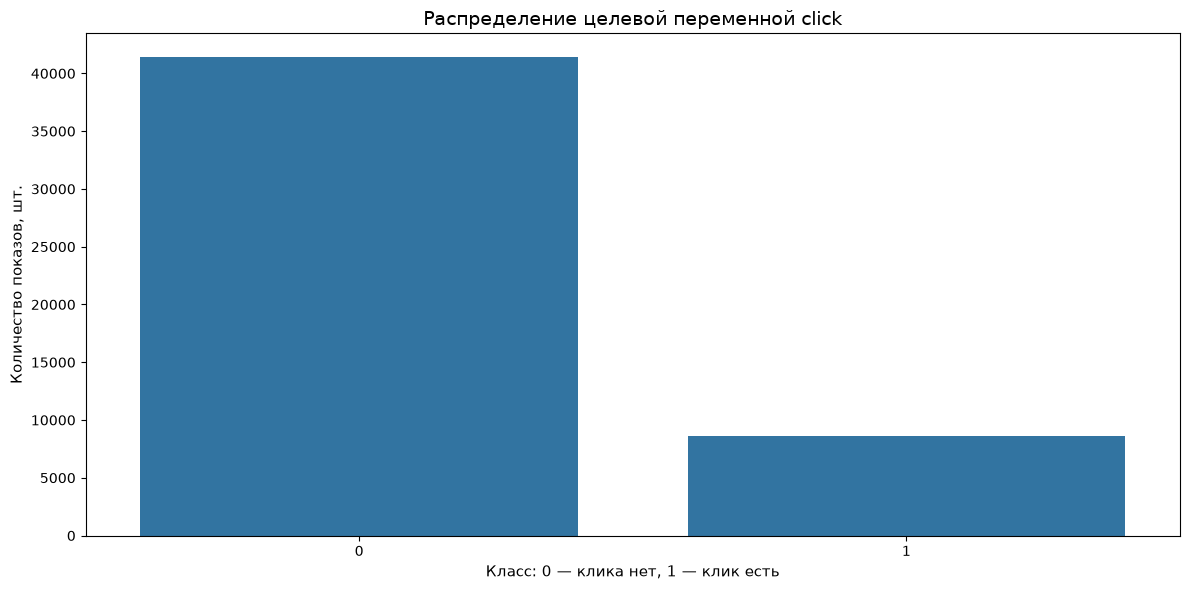

CTR: 17.21%


In [7]:
target_counts = df['click'].value_counts().sort_index()
target_share = df['click'].value_counts(normalize=True).sort_index() * 100

target_table = pd.DataFrame({
    'Количество показов': target_counts,
    'Доля, %': target_share.round(2)
})

display(target_table)

ax = sns.countplot(data=df, x='click')
ax.set_title('Распределение целевой переменной click')
ax.set_xlabel('Класс: 0 — клика нет, 1 — клик есть')
ax.set_ylabel('Количество показов, шт.')
plt.tight_layout()
plt.show()

ctr = df['click'].mean()
print(f'CTR: {ctr:.2%}')

**Вывод.** Доля кликов составляет около **17,21%**, а показов без клика — около **82,79%**.  
В данных есть заметный дисбаланс классов, поэтому на этапе моделирования не следует ориентироваться только на Accuracy. Для оценки классификации и качества вероятностей потребуются метрики, чувствительные к положительному классу и калибровке.

### 2.3 Анализ признаков и первичный отбор

In [8]:
cardinality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(dropna=False),
    'unique_share_%': (df.nunique(dropna=False) / len(df) * 100).round(2)
}).sort_values('n_unique', ascending=False)

display(cardinality)

,dtype,n_unique,unique_share_%
id,float64,50000,100.00
ml_feature_1,float64,50000,100.00
ml_feature_9,float64,50000,100.00
ml_feature_8,float64,50000,100.00
ml_feature_6,float64,50000,100.00
ml_feature_5,float64,50000,100.00
ml_feature_3,float64,50000,100.00
ml_feature_10,float64,50000,100.00
device_ip,object,41455,82.91
device_id,object,8580,17.16


`id` имеет уникальное значение для каждого наблюдения и не содержит обобщаемого сигнала — его можно исключить.

`device_ip` имеет очень высокую кардинальность: более 80% значений уникальны. Для линейной модели такой признак создаёт высокий риск переобучения и плохо переносится на новые адреса, поэтому на данном этапе он также исключается.

`site_id`, `site_domain`, `app_id`, `device_id` и `device_model` являются идентификаторами категорий, но **не удаляются автоматически**: контекст площадки, приложения и устройства может быть связан с CTR. Их полезность нужно проверять на кросс-валидации с корректным кодированием.

`hour` — не идентификатор. Из него можно извлечь понятные временные признаки.

,hour_of_day,ctr,shows
0,0,0.187386,1094
1,1,0.193576,1183
2,2,0.179874,1590
3,3,0.167574,1653
4,4,0.172414,2378
5,5,0.176070,2499
6,6,0.175909,2200
7,7,0.184673,2388
8,8,0.163314,2535
9,9,0.149752,2818


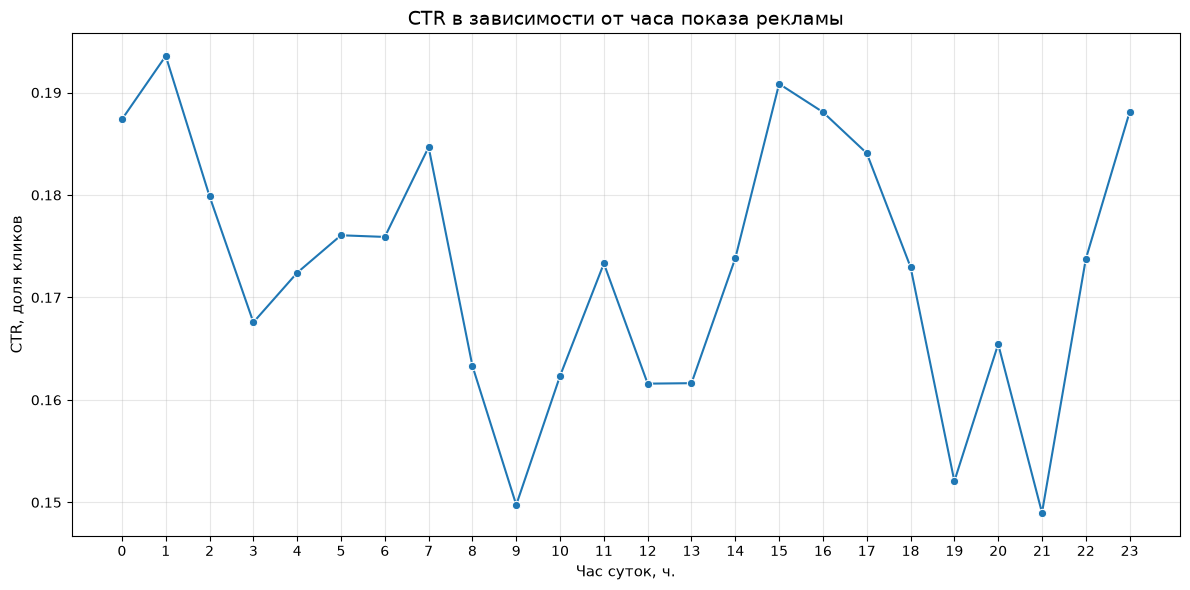

In [9]:
df_eda = df.drop(columns=['id', 'device_ip']).copy()

df_eda['event_datetime'] = pd.to_datetime(
    df_eda['hour'].astype(str),
    format='%y%m%d%H'
)
df_eda['hour_of_day'] = df_eda['event_datetime'].dt.hour
df_eda['day_of_week'] = df_eda['event_datetime'].dt.dayofweek

hour_ctr = (
    df_eda
    .groupby('hour_of_day')['click']
    .agg(
        ctr='mean',
        shows='count'
    )
    .reset_index()
)

display(hour_ctr)

plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=hour_ctr,
    x='hour_of_day',
    y='ctr',
    marker='o'
)

ax.set_title('CTR в зависимости от часа показа рекламы')
ax.set_xlabel('Час суток, ч.')
ax.set_ylabel('CTR, доля кликов')

plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Временной признак сохранён через производные `hour_of_day` и `day_of_week`. Исходный `hour` содержит одновременно дату и час и в таком кодовом виде не должен подаваться в линейную модель как обычное число.

### 2.4 Анализ пропущенных значений

In [10]:
missing_report = pd.DataFrame({
    'Пропусков': df.isna().sum(),
    'Доля пропусков, %': (df.isna().mean() * 100).round(2)
})

display(missing_report[missing_report['Пропусков'] > 0])

object_cols = df.select_dtypes(include='object').columns
blank_counts = {
    col: df[col].astype(str).str.strip().eq('').sum()
    for col in object_cols
}

blank_report = pd.Series(blank_counts, name='Пустых/пробельных строк')
display(blank_report[blank_report > 0])

print(f'Всего NaN: {int(df.isna().sum().sum())}')
print(f'Всего пустых/пробельных строк: {int(blank_report.sum())}')

,Пропусков,"Доля пропусков, %"


Series([], Name: Пустых/пробельных строк, dtype: int64)

Всего NaN: 0
Всего пустых/пробельных строк: 0


**Вывод.** Формальных пропусков и пустых строк не обнаружено, поэтому заполнять значения на текущем этапе не требуется.

В `C20` присутствует значение `-1`. Поскольку признак анонимизирован, без словаря данных нельзя считать `-1` ошибкой или пропуском. Значение оставляется без изменений как отдельный код.

### 2.5 Типизация и анализ категориальных признаков

In [11]:
continuous_cols = [
    'ml_feature_1',
    'ml_feature_3',
    'ml_feature_5',
    'ml_feature_6',
    'ml_feature_8',
    'ml_feature_9',
    'ml_feature_10'
]

binary_cols = [
    'ml_feature_4'
]

categorical_cols = [
    'C1',
    'banner_pos',
    'site_id',
    'site_domain',
    'site_category',
    'app_id',
    'app_domain',
    'app_category',
    'device_id',
    'device_model',
    'device_type',
    'device_conn_type',
    'C14',
    'C15',
    'C16',
    'C17',
    'C18',
    'C19',
    'C20',
    'C21',
    'ml_feature_2',
    'ml_feature_7',
    'hour_of_day',
    'day_of_week'
]

cat_cardinality = (
    df_eda[categorical_cols]
    .nunique()
    .sort_values()
    .rename('Количество категорий')
    .to_frame()
)

display(cat_cardinality)

,Количество категорий
ml_feature_7,3
device_conn_type,4
C18,4
device_type,4
ml_feature_2,5
C1,7
day_of_week,7
banner_pos,7
C15,8
C16,9


In [12]:
ohe_candidates = cat_cardinality[
    cat_cardinality['Количество категорий'] <= 30
].index.tolist()

high_cardinality_candidates = cat_cardinality[
    cat_cardinality['Количество категорий'] > 30
].index.tolist()

print('Кандидаты на One-Hot Encoding:')
print(ohe_candidates)

print('\nПризнаки средней/высокой кардинальности:')
print(high_cardinality_candidates)

Кандидаты на One-Hot Encoding:
['ml_feature_7', 'device_conn_type', 'C18', 'device_type', 'ml_feature_2', 'C1', 'day_of_week', 'banner_pos', 'C15', 'C16', 'site_category', 'app_category', 'hour_of_day']

Признаки средней/высокой кардинальности:
['C21', 'C19', 'app_domain', 'C20', 'C17', 'app_id', 'site_domain', 'site_id', 'C14', 'device_model', 'device_id']


**Предварительная стратегия кодирования:**

- признаки с низкой и умеренной кардинальностью рассматриваются для `OneHotEncoder`;
- признаки с высокой кардинальностью, для которых OHE создаёт слишком большое число столбцов, рассматриваются для `TargetEncoder`;
- граница между способами кодирования не задаётся одним жёстким числом: окончательный выбор делается с учётом фактической кардинальности и вычислительной стоимости;
- Target Encoding должен обучаться только на тренировочной части данных, чтобы не допустить утечки целевой переменной.


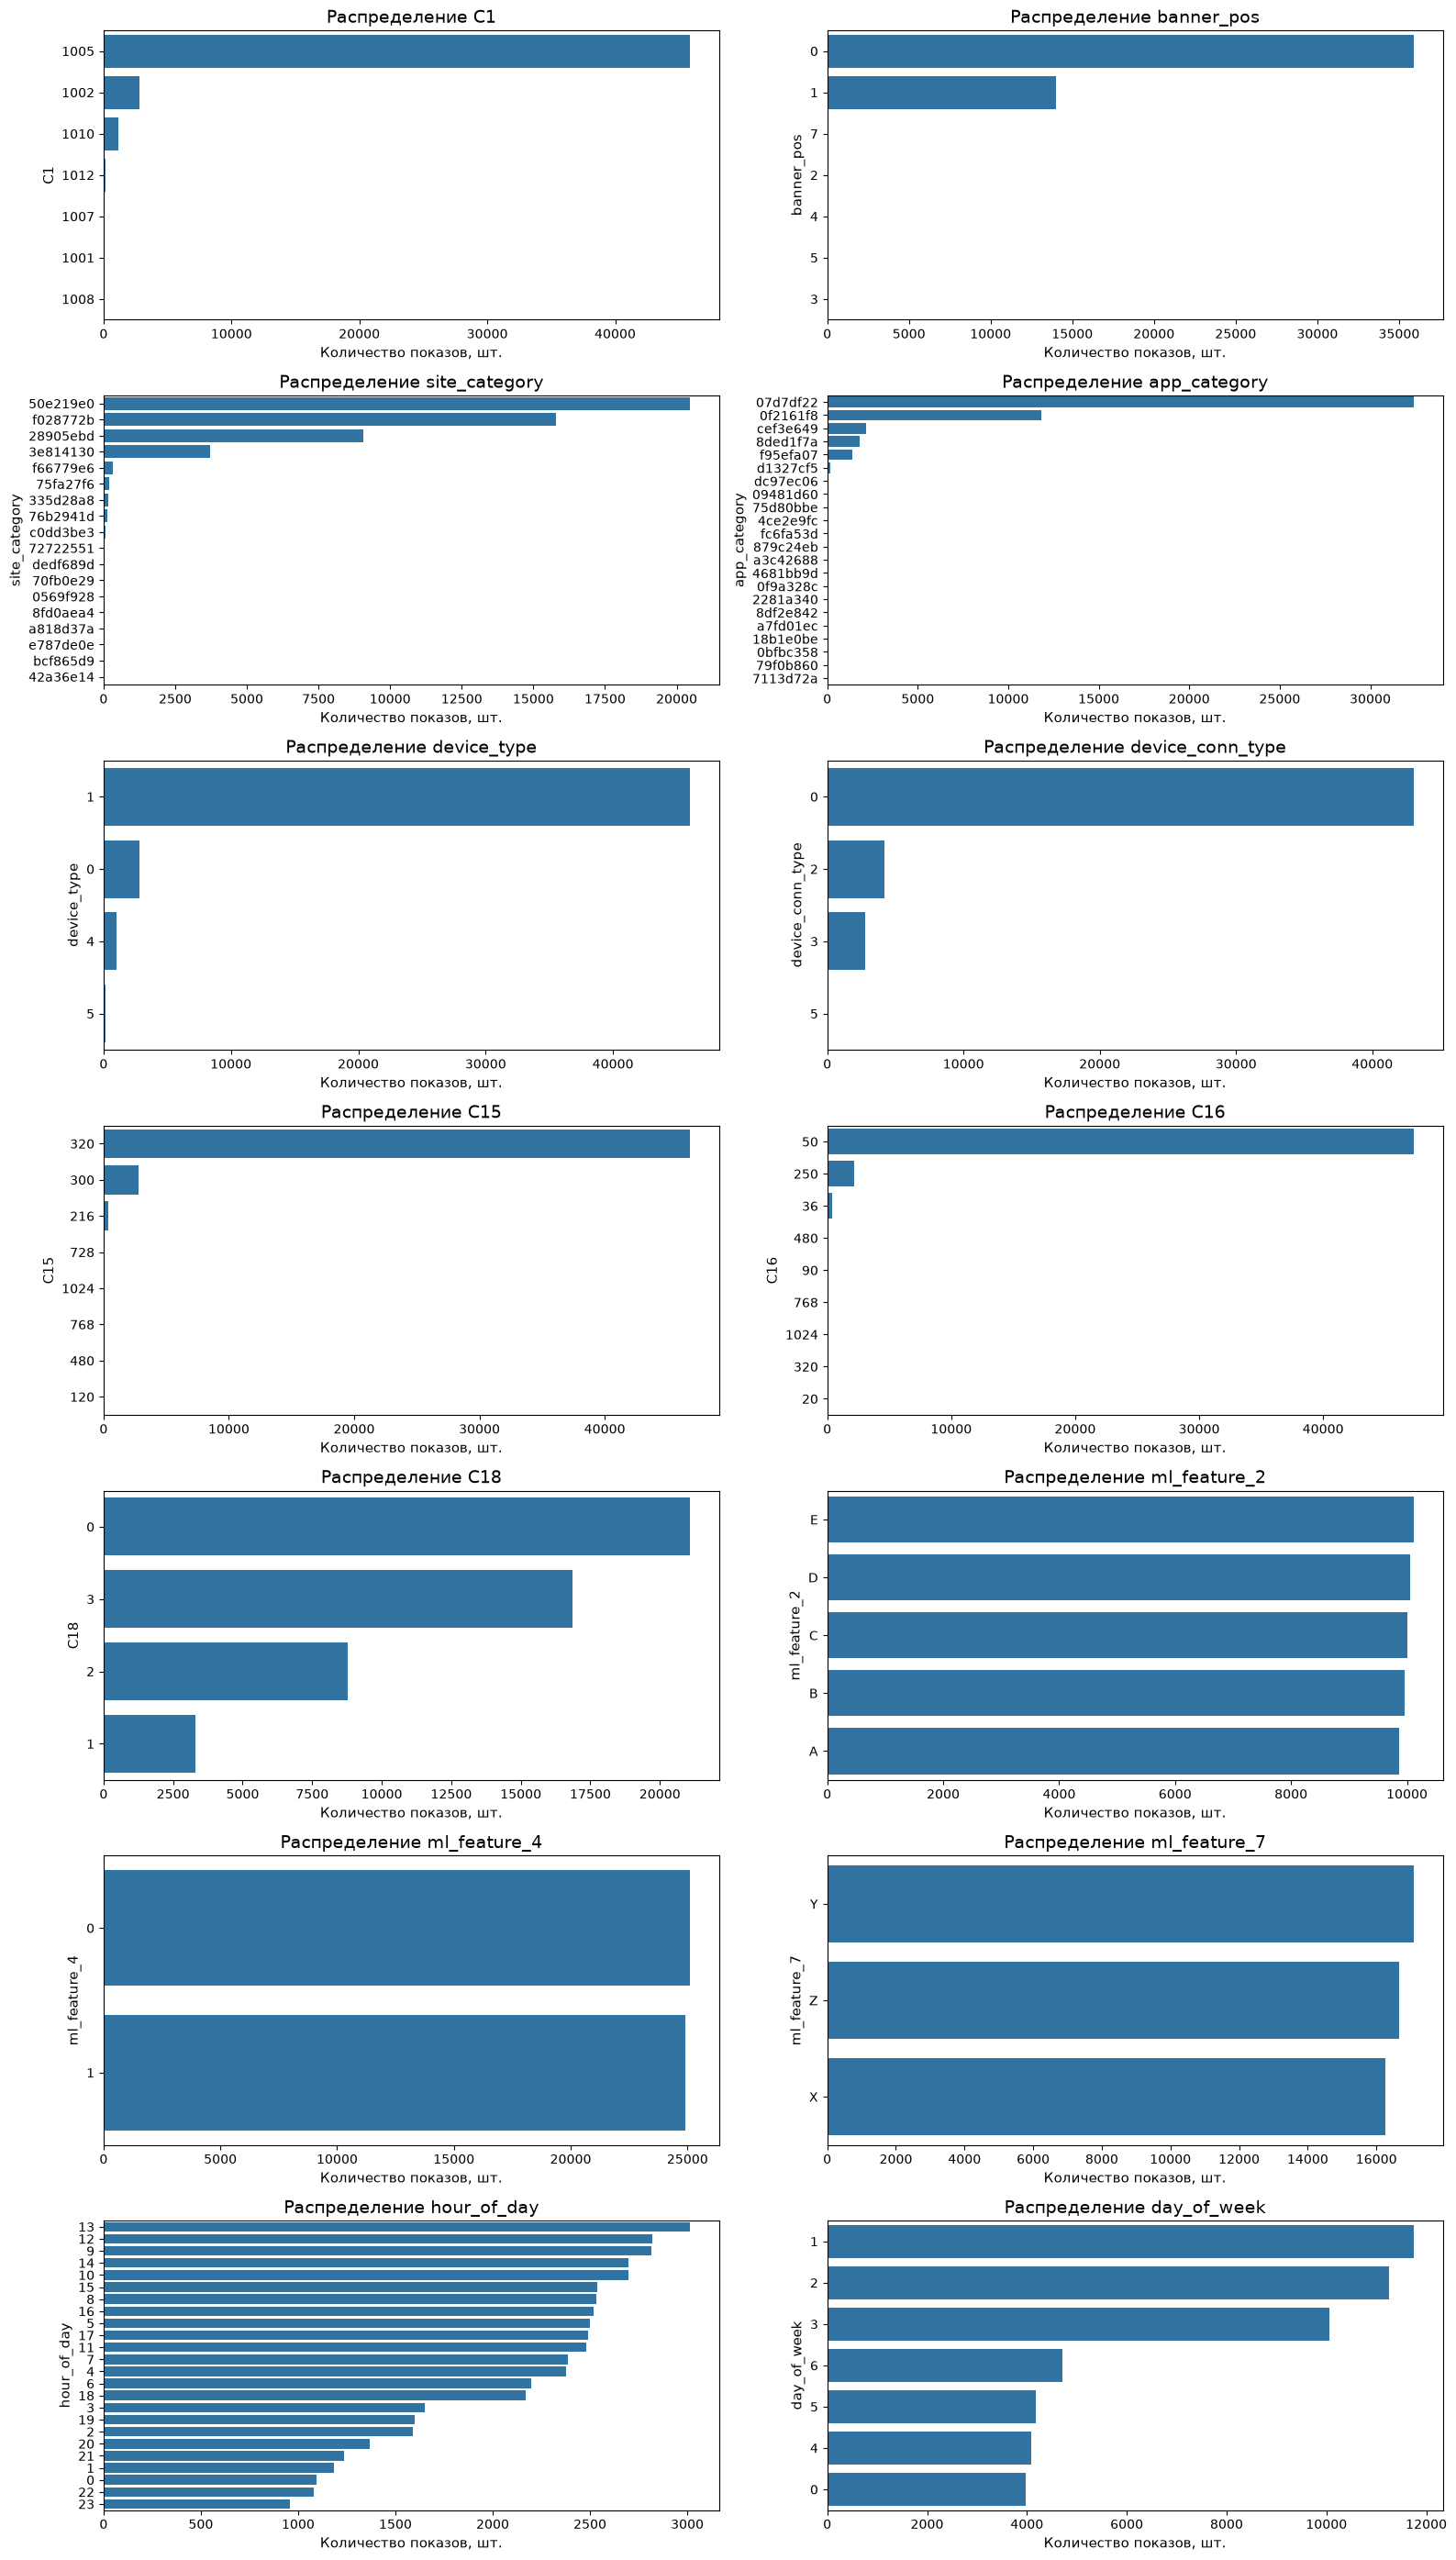

In [13]:
low_card_plot_cols = [
    'C1',
    'banner_pos',
    'site_category',
    'app_category',
    'device_type',
    'device_conn_type',
    'C15',
    'C16',
    'C18',
    'ml_feature_2',
    'ml_feature_4',
    'ml_feature_7',
    'hour_of_day',
    'day_of_week'
]

n_cols = 2
n_rows = int(np.ceil(len(low_card_plot_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, low_card_plot_cols):
    order = df_eda[feature].value_counts().index
    sns.countplot(data=df_eda, y=feature, order=order, ax=ax)
    ax.set_title(f'Распределение {feature}')
    ax.set_xlabel('Количество показов, шт.')
    ax.set_ylabel(feature)

for ax in axes[len(low_card_plot_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

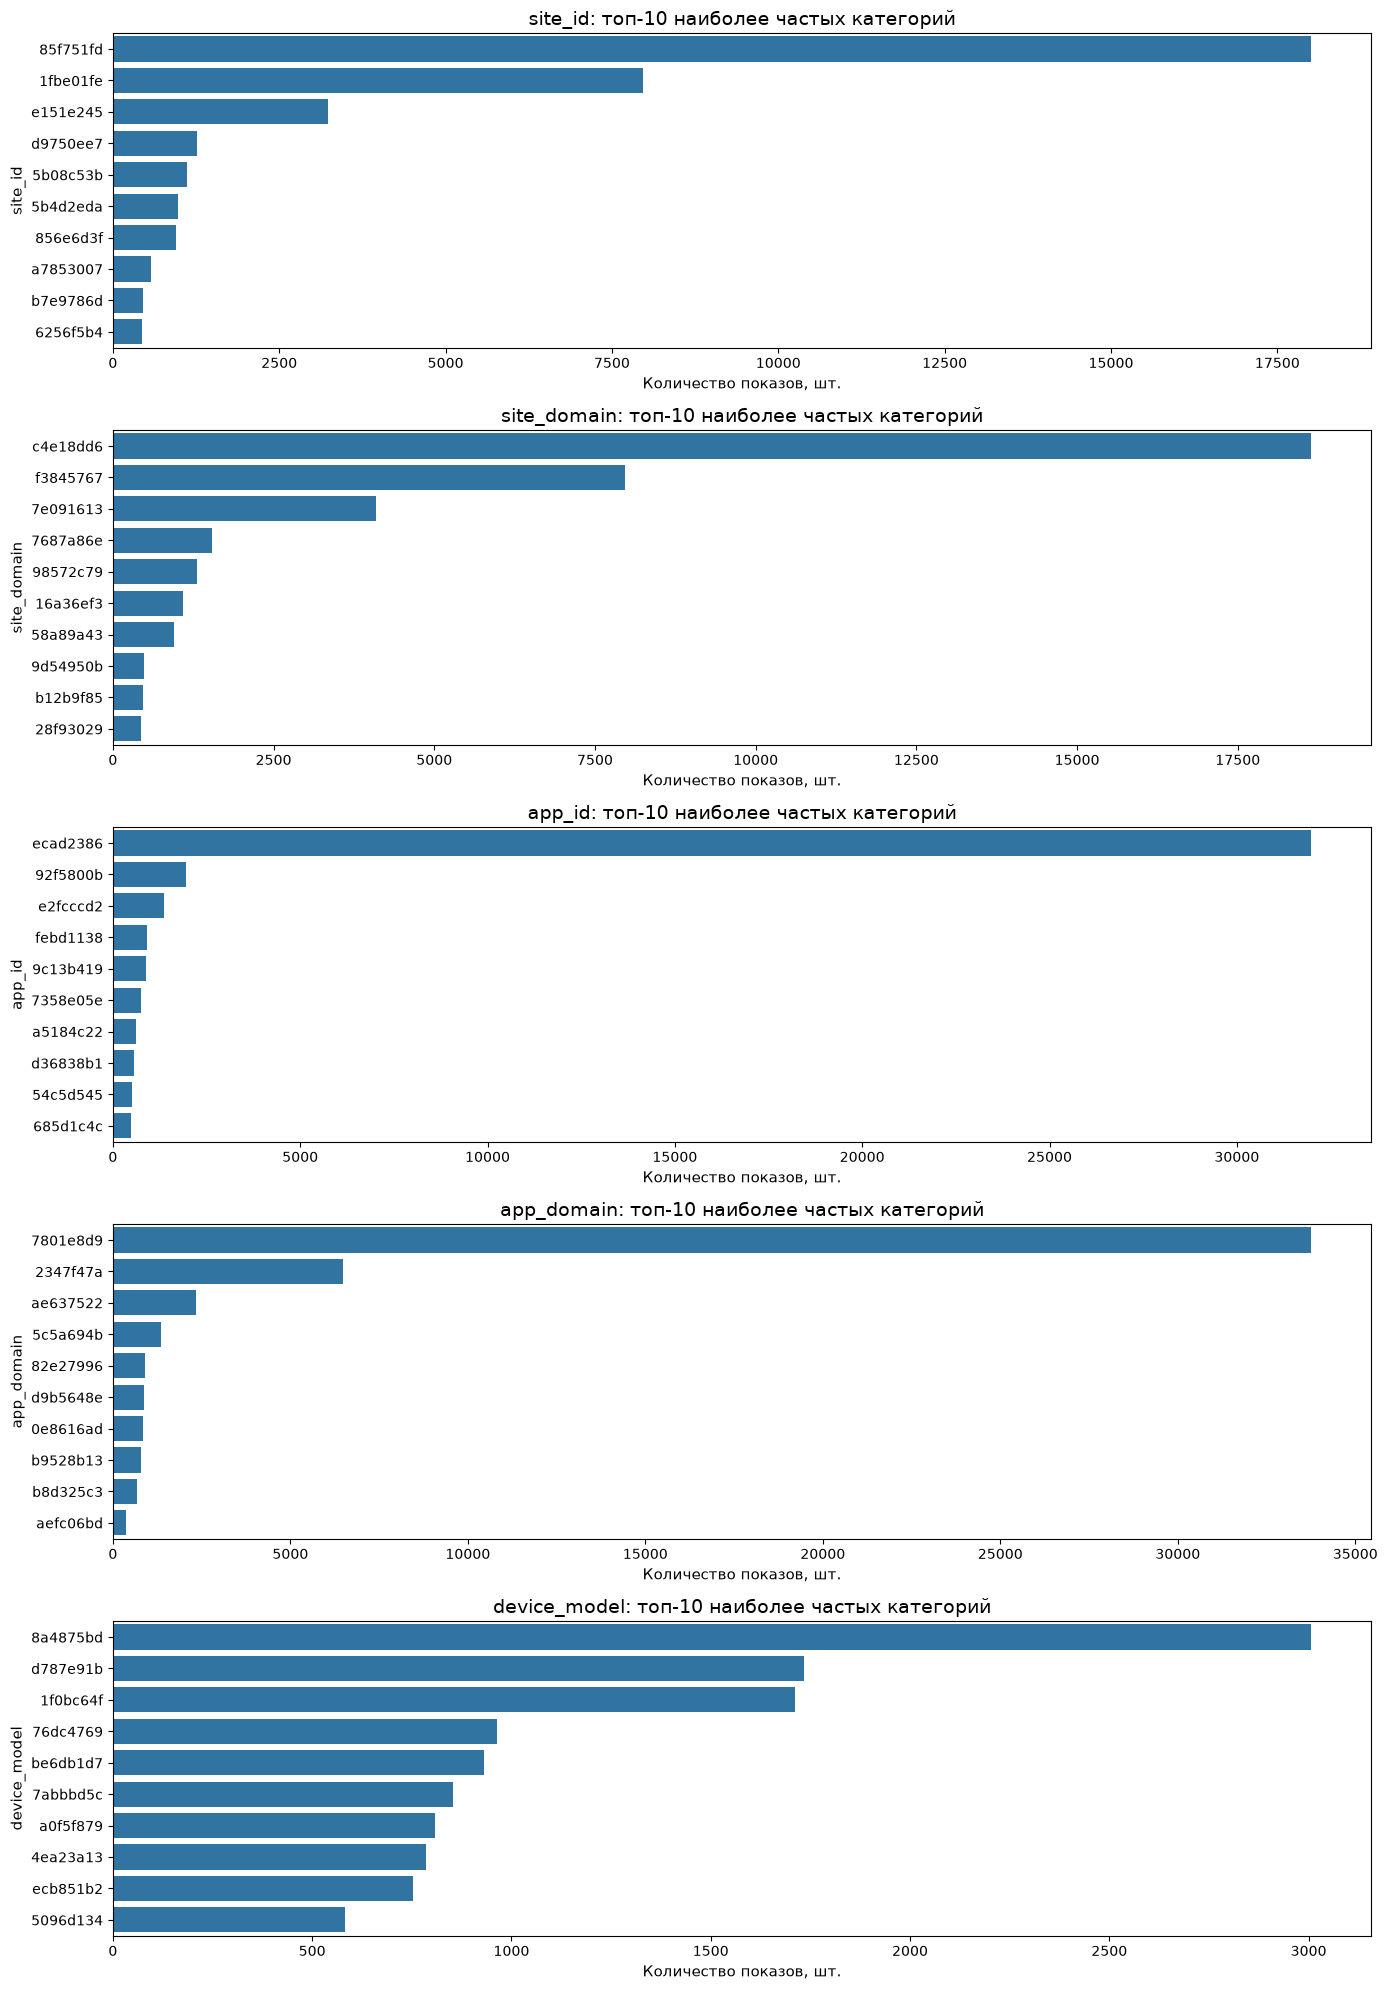

In [14]:
high_card_plot_cols = [
    'site_id',
    'site_domain',
    'app_id',
    'app_domain',
    'device_model'
]

TOP_K = 10
fig, axes = plt.subplots(
    len(high_card_plot_cols),
    1,
    figsize=(14, 4 * len(high_card_plot_cols))
)
axes = np.atleast_1d(axes)

for ax, feature in zip(axes, high_card_plot_cols):
    top_values = df_eda[feature].value_counts().head(TOP_K).index
    sns.countplot(data=df_eda, y=feature, order=top_values, ax=ax)
    ax.set_title(f'{feature}: топ-{TOP_K} наиболее частых категорий')
    ax.set_xlabel('Количество показов, шт.')
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

### 2.6 Распределения и выбросы непрерывных признаков

In [15]:
display(df_eda[continuous_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
ml_feature_1,50000.0,-0.002445,1.000280,-4.631262,-0.677784,-0.003776,0.673534,3.793828
ml_feature_3,50000.0,-0.036381,5.792335,-9.999742,-5.059555,-0.056155,4.985939,9.999975
ml_feature_5,50000.0,0.034729,1.002116,-4.631853,-0.639829,0.028112,0.707594,4.230623
ml_feature_6,50000.0,0.022948,0.656690,-1.000000,-0.579775,0.037786,0.637131,1.000000
ml_feature_8,50000.0,0.025465,0.578026,-0.999965,-0.470627,0.027348,0.521117,1.119858
ml_feature_9,50000.0,0.035361,0.505034,-2.147526,-0.304077,0.035985,0.374152,2.120786
ml_feature_10,50000.0,0.020226,0.303309,-1.287965,-0.182386,0.018930,0.224080,1.202300


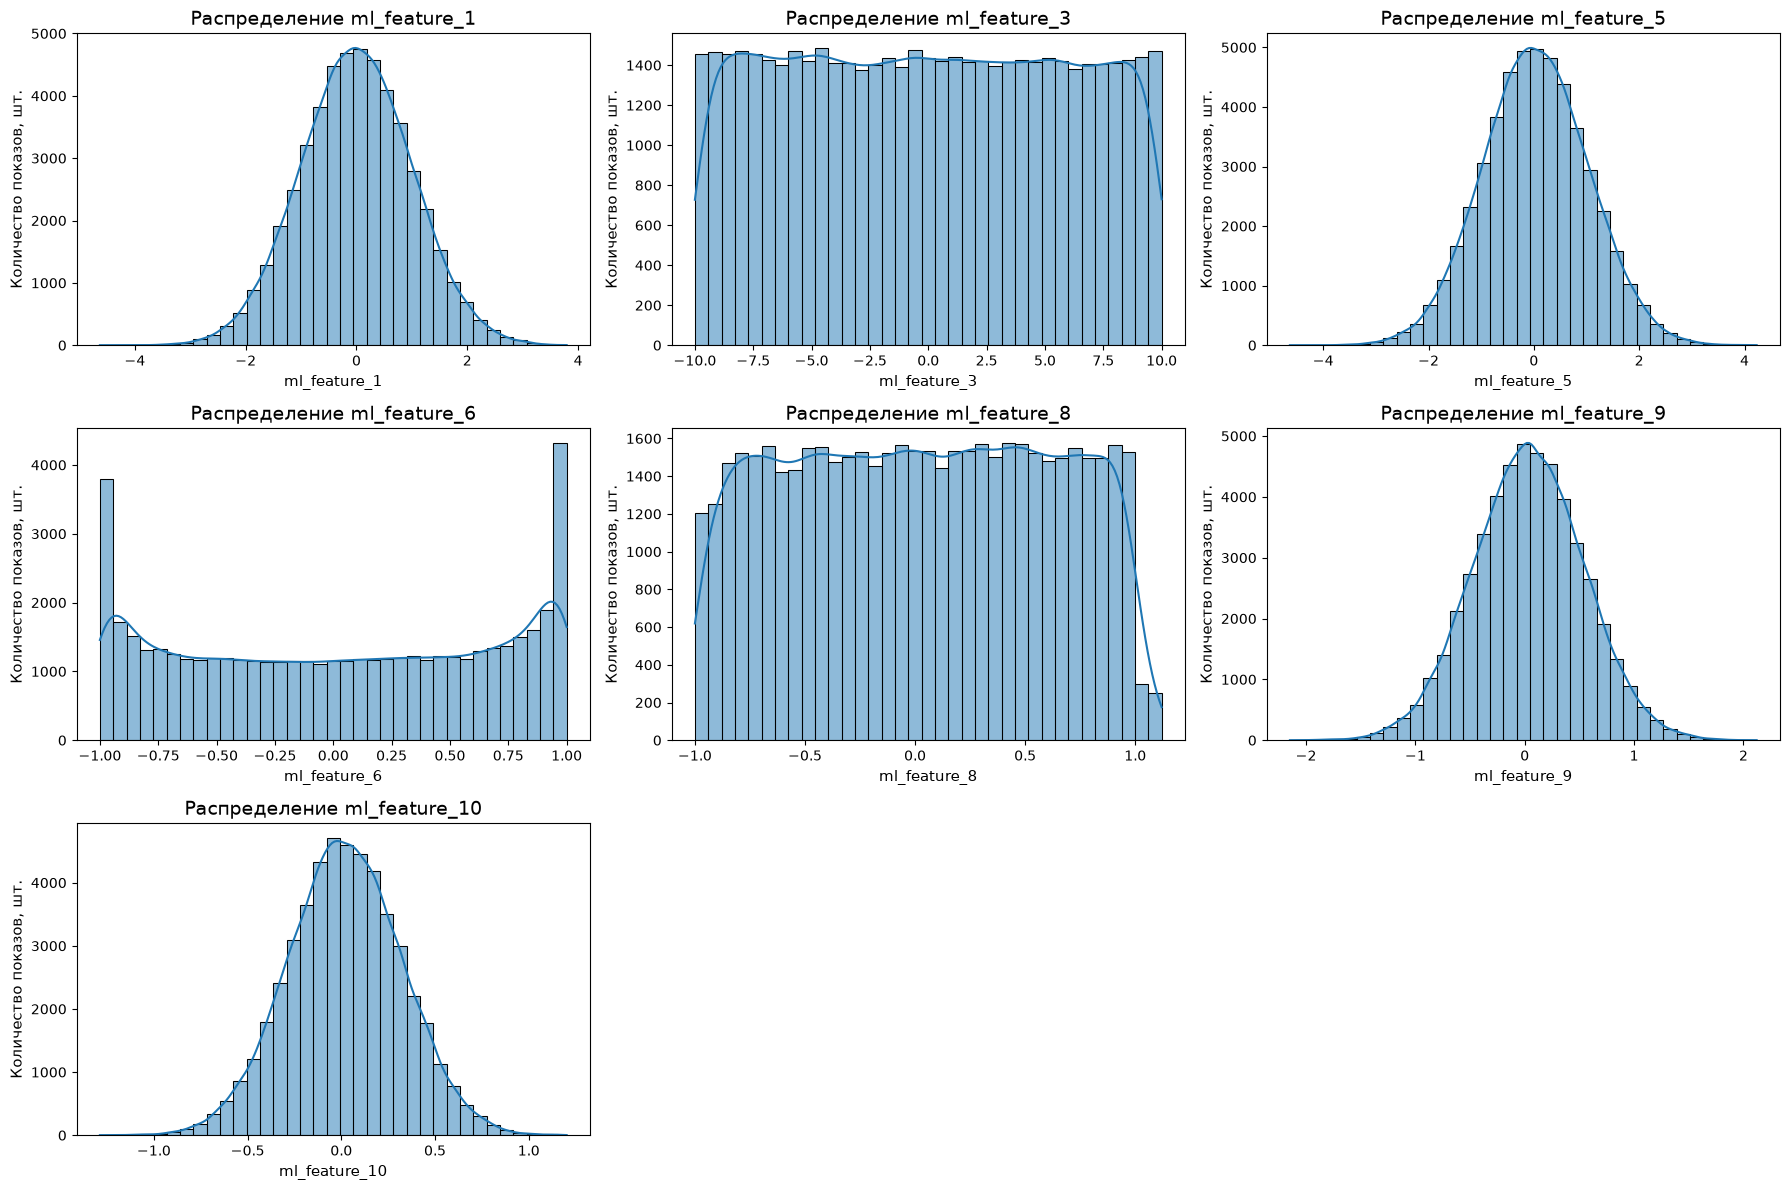

In [16]:
n_cols = 3
n_rows = int(np.ceil(len(continuous_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, continuous_cols):
    sns.histplot(data=df_eda, x=feature, bins=35, kde=True, ax=ax)
    ax.set_title(f'Распределение {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Количество показов, шт.')

for ax in axes[len(continuous_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

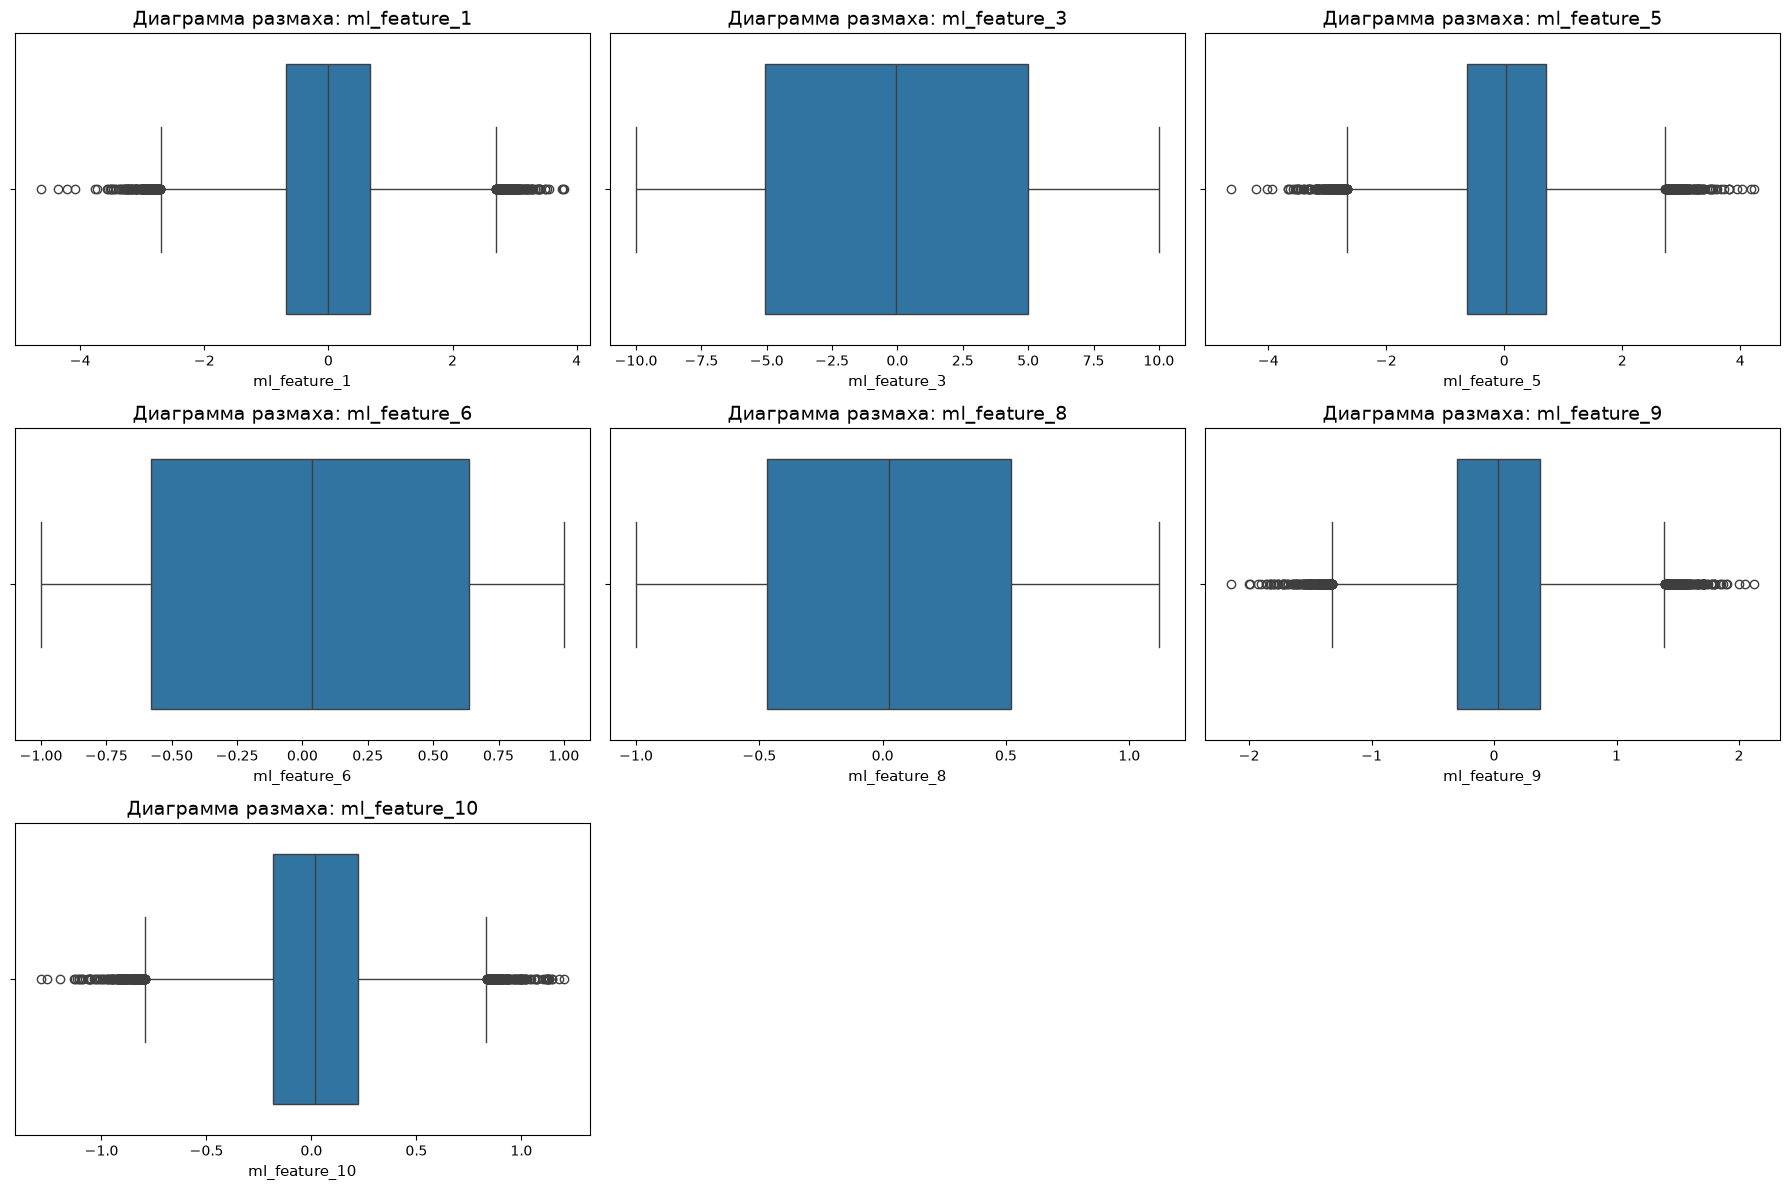

In [17]:
n_cols = 3
n_rows = int(np.ceil(len(continuous_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, continuous_cols):
    sns.boxplot(data=df_eda, x=feature, ax=ax)
    ax.set_title(f'Диаграмма размаха: {feature}')
    ax.set_xlabel(feature)

for ax in axes[len(continuous_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [18]:
outlier_rows = []

for feature in continuous_cols:
    q1 = df_eda[feature].quantile(0.25)
    q3 = df_eda[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_share = (
        (df_eda[feature] < lower) |
        (df_eda[feature] > upper)
    ).mean() * 100

    outlier_rows.append({
        'Признак': feature,
        'Нижняя граница IQR': lower,
        'Верхняя граница IQR': upper,
        'Доля за границами, %': outlier_share
    })

outlier_report = pd.DataFrame(outlier_rows)
outlier_report['Доля за границами, %'] = (
    outlier_report['Доля за границами, %'].round(2)
)

display(outlier_report)

,Признак,Нижняя граница IQR,Верхняя граница IQR,"Доля за границами, %"
0,ml_feature_1,-2.704761,2.700512,0.69
1,ml_feature_3,-20.127795,20.054179,0.00
2,ml_feature_5,-2.660964,2.728728,0.72
3,ml_feature_6,-2.405134,2.462490,0.00
4,ml_feature_8,-1.958243,2.008733,0.00
5,ml_feature_9,-1.321420,1.391495,0.77
6,ml_feature_10,-0.792087,0.833781,0.70


**Вывод.** По непрерывным `ml_feature_*` проверены распределения и значения за границами правила 1.5 IQR. Сам факт попадания точки за границу IQR не означает ошибку, поэтому автоматическое удаление таких наблюдений не выполняется.

Признаки `C1`, `banner_pos`, `C14`–`C21`, `device_type` и `device_conn_type` не анализируются как непрерывные через boxplot: их значения трактуются как дискретные коды.

### 2.7 Связь признаков с целевой переменной

Для настоящих непрерывных признаков рассчитываются Pearson и Spearman.

Для смешанного набора числовых и категориальных признаков используется Phi-k. Большинство анонимизированных `C*` интерпретируются как дискретные коды. `C14` семантически также остаётся кодовым признаком, однако в расчёте Phi-k он временно включён в `interval_cols` как вычислительное приближение из-за большого числа уникальных значений. Это техническое решение для расчёта матрицы и не означает, что `C14` далее трактуется как непрерывная величина.


,Pearson,Spearman
ml_feature_9,0.1459,0.1407
ml_feature_10,0.1309,0.1267
ml_feature_8,0.0801,0.0779
ml_feature_6,0.0716,0.0719
ml_feature_5,0.0625,0.0603
ml_feature_3,0.0029,0.0029
ml_feature_1,0.0021,0.0009


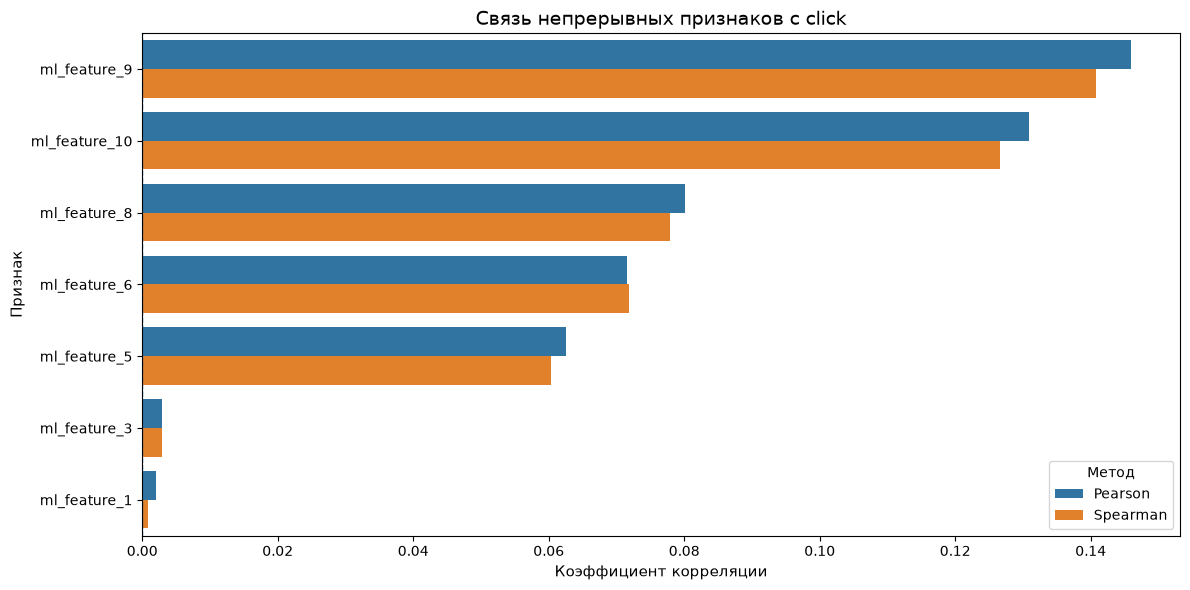

In [19]:
pearson_corr = (
    df_eda[continuous_cols + ['click']]
    .corr(method='pearson')['click']
    .drop('click')
)

spearman_corr = (
    df_eda[continuous_cols + ['click']]
    .corr(method='spearman')['click']
    .drop('click')
)

corr_table = pd.DataFrame({
    'Pearson': pearson_corr,
    'Spearman': spearman_corr
})

corr_table['max_abs_corr'] = corr_table.abs().max(axis=1)
corr_table = corr_table.sort_values('max_abs_corr', ascending=False)

display(corr_table.drop(columns='max_abs_corr').round(4))

plot_corr = corr_table.drop(columns='max_abs_corr').reset_index()
plot_corr = plot_corr.melt(
    id_vars='index',
    var_name='Метод',
    value_name='Корреляция'
)

ax = sns.barplot(
    data=plot_corr,
    x='Корреляция',
    y='index',
    hue='Метод'
)
ax.set_title('Связь непрерывных признаков с click')
ax.set_xlabel('Коэффициент корреляции')
ax.set_ylabel('Признак')
ax.axvline(0, linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

In [20]:

continuous_cols = [
    'C14',
    'ml_feature_1',
    'ml_feature_3',
    'ml_feature_5',
    'ml_feature_6',
    'ml_feature_8',
    'ml_feature_9',
    'ml_feature_10'
]

phik_categorical_cols = [
    'site_category',
    'app_domain',
    'app_category',
    'device_type',
    'device_conn_type',

    'C1',
    'banner_pos',
    'C15',
    'C16',
    'C17',
    'C18',
    'C19',
    'C20',
    'C21',

    'ml_feature_2',
    'ml_feature_4',
    'ml_feature_7'
]

# Высококардинальные признаки не включаем
# в общую Phi-k матрицу из-за вычислительной нагрузки
high_cardinality_cols = [
    'site_id',
    'site_domain',
    'app_id',
    'device_model'
]

target = 'click'

In [21]:
phik_features = (
    continuous_cols
    + phik_categorical_cols
    + [target]
)

df_phi = df_eda[phik_features].copy()

phi_matrix = df_phi.phik_matrix(
    interval_cols=continuous_cols
)

corr_with_target = (
    phi_matrix[target]
    .drop(target)
    .sort_values(ascending=False)
)

print('Связь признаков с целевой переменной:')
display(corr_with_target)

Связь признаков с целевой переменной:


C17                 0.323409
C18                 0.257840
C21                 0.242703
C19                 0.217140
ml_feature_9        0.187801
ml_feature_10       0.169983
C15                 0.165941
app_domain          0.161289
app_category        0.156537
site_category       0.155008
C20                 0.154375
ml_feature_8        0.153598
C16                 0.144262
device_conn_type    0.129954
C14                 0.112890
ml_feature_6        0.091314
ml_feature_5        0.080014
device_type         0.071790
C1                  0.045931
ml_feature_7        0.022622
banner_pos          0.022605
ml_feature_1        0.010056
ml_feature_2        0.003790
ml_feature_3        0.000000
ml_feature_4        0.000000
Name: click, dtype: float64

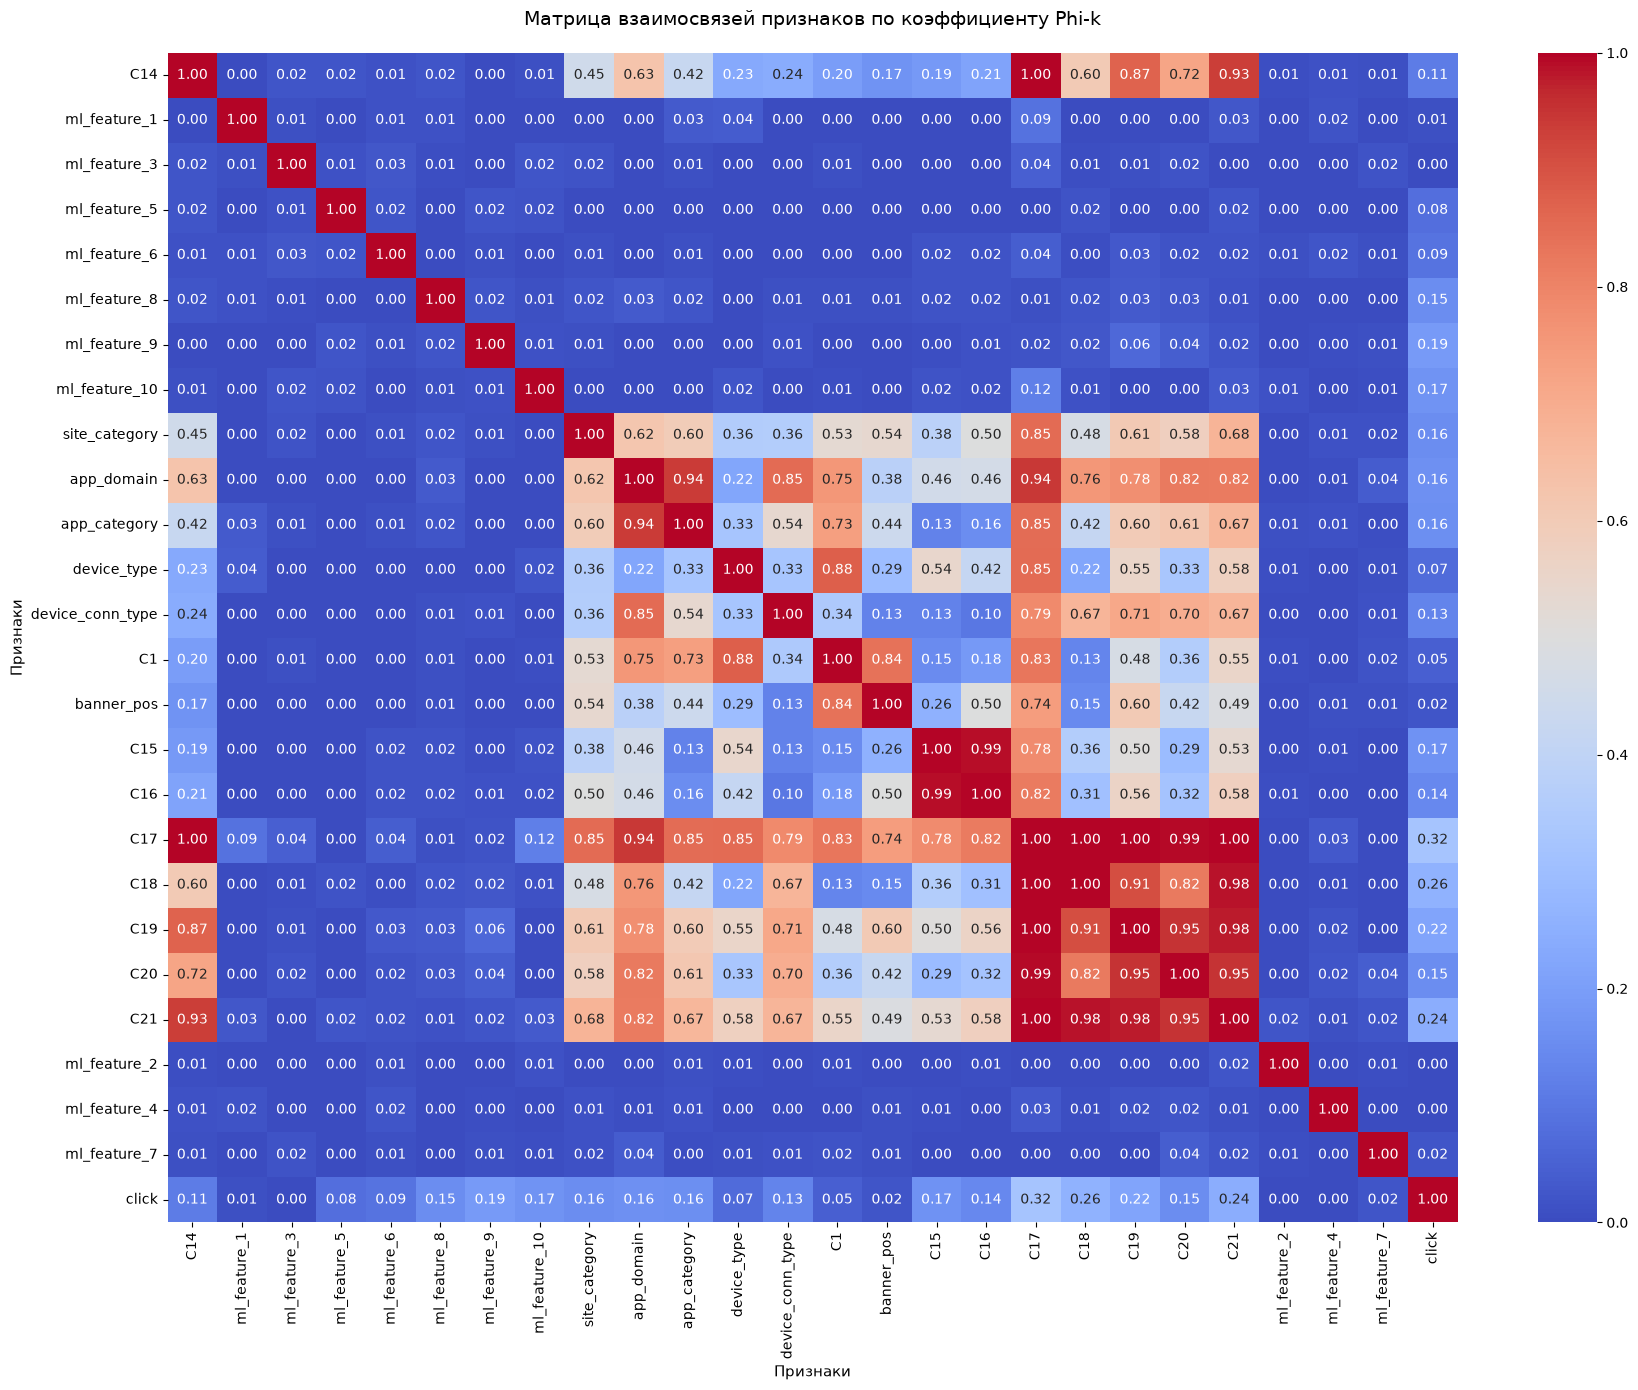

In [22]:
plt.figure(figsize=(18, 14))

ax = sns.heatmap(
    phi_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

ax.set_title(
    'Матрица взаимосвязей признаков по коэффициенту Phi-k',
    pad=20
)

ax.set_xlabel('Признаки')
ax.set_ylabel('Признаки')

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

`device_id` не включён в полную Phi-k матрицу из-за высокой кардинальности и высокой вычислительной стоимости попарного расчёта. Это не означает автоматического удаления признака: его пользу корректнее оценивать позже через кросс-валидацию с подходящим кодированием.

### 2.8 Выводы по EDA

1. В выборке содержится **50 000 рекламных показов и 34 исходных столбца**. Целевая переменная `click` бинарная.

2. CTR составляет около **17,21%**. Класс клика представлен заметно реже класса отсутствия клика, поэтому Accuracy не должна быть единственной метрикой качества.

3. Формальных `NaN`, пустых и пробельных строк не обнаружено. Значение `-1` в `C20` не заменяется автоматически, поскольку без описания анонимизированного признака нельзя подтвердить, что это ошибка или пропуск.

4. `id` исключается как уникальный идентификатор события. `device_ip` исключается из-за почти уникальных значений и высокого риска переобучения. Остальные идентификаторы площадки, приложения и устройства сохраняются до проверки их полезности на кросс-валидации.

5. `hour` не удаляется как бесполезный идентификатор. Из него извлечены `hour_of_day` и `day_of_week`, поскольку время показа потенциально связано с CTR.

6. Непрерывными считаются `ml_feature_1`, `ml_feature_3`, `ml_feature_5`, `ml_feature_6`, `ml_feature_8`, `ml_feature_9`, `ml_feature_10`. `ml_feature_4` является бинарным. Анонимизированные `C1`, `C14`–`C21` рассматриваются как дискретные кодовые признаки.

7. Для категорий с низкой и умеренной кардинальностью используется One-Hot Encoding. Для высококардинальных признаков (`site_id`, `site_domain`, `app_id`, `device_id`, `device_model` и часть `C*`) применяется более компактное Target Encoding. Target Encoding допустим только внутри обучающего Pipeline.

8. По текущему Pearson-анализу наиболее заметная линейная связь среди непрерывных признаков наблюдается у `ml_feature_9` и `ml_feature_10`; более слабая — у `ml_feature_8`, `ml_feature_6` и `ml_feature_5`. Слабая парная корреляция сама по себе не является основанием для удаления признака.

9. В Phi-k настоящие непрерывные `ml_feature_*` задаются как интервальные. `C14` временно включён в `interval_cols` только как вычислительное приближение из-за высокой кардинальности; семантически он остаётся дискретным кодовым признаком. Высококардинальные идентификаторы не включаются в полную матрицу из-за вычислительной нагрузки и оцениваются далее через модели.

10. На следующих этапах обработку категориальных признаков, масштабирование и любой Target Encoding необходимо выполнять внутри Pipeline и обучать только на тренировочной части данных.


## 3. Разделение данных на выборки

#### 3.1 Разделите данные
- Сначала отделите тестовую выборку, в ней должно быть 20% данных.
- Оставшиеся 80% данных используйте для обучения.
- Используйте стратифицированное разделение, чтобы сохранить баланс классов.
- **Не используйте тестовую выборку до финального тестирования!**

#### 3.2 Проверьте разделение
- Убедитесь, что распределение целевой переменной сохранено в каждой выборке.
- Выведите размеры выборок.

In [23]:
X= df_eda.drop(columns=['click'])
y = df_eda['click']

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

In [24]:
print(X_train_val.shape[0])
print(y_train_val.shape[0])
print(X_test.shape[0])
print(y_test.shape[0])

40000
40000
10000
10000


In [25]:
print('Train/val:')
print(y_train_val.value_counts(normalize=True).round(4))

print('\nTest:')
print(y_test.value_counts(normalize=True).round(4))

Train/val:
click
0    0.828
1    0.172
Name: proportion, dtype: float64

Test:
click
0    0.8279
1    0.1721
Name: proportion, dtype: float64


**Вывод по разделению данных.**

Данные разделены стратифицированно: в `train/val` вошло **40 000 наблюдений**, в тестовую выборку — **10 000**. Доля положительного класса сохранилась практически неизменной: около **17,2%** в обеих частях.

Тестовая выборка далее должна оставаться изолированной до финальной оценки. Все решения по предобработке, отбору признаков, гиперпараметрам и порогу классификации принимаются только по `train/val`.


## 4. Предобработка данных — построение пайплайнов

#### 4.1 Создайте пайплайн для предобработки данных

**Для числовых признаков:**
- Корректно заполните пропуски — средним, медианой или другим методом.
- Масштабируйте данные с помощью `StandardScaler`.
- Обработайте выбросы, если необходимо.

**Для категориальных признаков:**
- Корректно заполните пропуски — значением по умолчанию или модой.
- Примените кодирование:
  - One-Hot Encoding для признаков с малой кардинальностью.
  - Target Encoding для признаков с высокой кардинальностью.

#### 4.2 Объедините пайплайны
- Используйте `sklearn.pipeline.Pipeline` и `ColumnTransformer`.
- **Важно:** используйте информацию о пропусках и категориях только из обучающей выборки!

In [26]:
num_features = [
    'ml_feature_1','ml_feature_3',
    'ml_feature_5','ml_feature_6',
    'ml_feature_8','ml_feature_9',
    'ml_feature_10'
]
onehot_features = [
    'C1','banner_pos','site_category',
    'app_domain','app_category','device_type',
    'device_conn_type','C15','C16',
    'C18','C19','C21','ml_feature_2',
    'ml_feature_7','hour_of_day','day_of_week'
]
target_features = [
    'site_id','site_domain','app_id',
    'device_id','device_model','C14',
    'C17','C20'
]
binary_features = [
    'ml_feature_4'
]

print(f'Непрерывные значения для num - {num_features}')
print('='*50)
print(f'''Категоричальные признаки для методов:
--------------------------
OneHotEncoder {onehot_features}, 
--------------------------
Target_encoding - {target_features}''')


print('='*50)
print(f'Бинарные признаки: {binary_features}')


Непрерывные значения для num - ['ml_feature_1', 'ml_feature_3', 'ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10']
Категоричальные признаки для методов:
--------------------------
OneHotEncoder ['C1', 'banner_pos', 'site_category', 'app_domain', 'app_category', 'device_type', 'device_conn_type', 'C15', 'C16', 'C18', 'C19', 'C21', 'ml_feature_2', 'ml_feature_7', 'hour_of_day', 'day_of_week'], 
--------------------------
Target_encoding - ['site_id', 'site_domain', 'app_id', 'device_id', 'device_model', 'C14', 'C17', 'C20']
Бинарные признаки: ['ml_feature_4']


In [27]:
target_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


cat_ohe_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy = 'most_frequent')),
    ('onehot',OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])
cat_te_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy = 'most_frequent')),
    ('onehot',TargetEncoder(smooth=1.0, cv=target_cv))
])
num_pipeline= Pipeline([
    ('imputer',SimpleImputer(strategy = 'median')),
    ('scaler',StandardScaler())
])
special_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat_ohe', cat_ohe_pipeline, onehot_features),
        ('cat_te', cat_te_pipeline, target_features),
        ('special', special_pipeline , binary_features),
    ]
)

pipe_log = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(random_state=RANDOM_STATE))
])

pipe_dummy = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DummyClassifier(random_state=RANDOM_STATE))
])

pipe_svc = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', SVC(random_state=RANDOM_STATE))
])

**Вывод по предобработке.**

Для разных типов признаков сформирован единый `ColumnTransformer`. Непрерывные признаки заполняются медианой и масштабируются через `StandardScaler`; категориальные признаки с низкой и умеренной кардинальностью кодируются `OneHotEncoder`, а высококардинальные — `TargetEncoder`. Для бинарного признака предусмотрено заполнение константой.

`TargetEncoder` использует внутренний стратифицированный CV, что уменьшает риск переобучения при кодировании по целевой переменной. Все обучаемые преобразования далее включаются в `Pipeline`, поэтому при кросс-валидации они переобучаются только на тренировочной части каждого фолда.


## 5. Отбор признаков

#### 5.1 Примените фильтрационные методы
- Посчитайте корреляцию каждого признака с целевой переменной.
- Отберите топ лучших признаков. Объясните, почему остановились именно на таком количестве признаков.
- Удалите признаки с очень низкой вариацией `VarianceThreshold`.

#### 5.2 Примените методы-обёртки
- Используйте методы-обёртки для поиска оптимального набора признаков.

#### 5.3 Выберите финальный набор признаков
- Объедините результаты методов.
- Выберите признаки, которые прошли фильтрацию.

In [28]:
numerical_columns = df_eda.select_dtypes(include=[np.number]).columns
numerical_data = df_eda[numerical_columns]

vs_constant = VarianceThreshold(threshold=0.0) 
vs_constant.fit(numerical_data)

# Находим константные числовые признаки
constant_num_columns = [col for col, keep in zip(numerical_columns, vs_constant.get_support()) if not keep]

# Категориальные признаки
constant_cat_columns = [col for col in df_eda.select_dtypes(include=['object']).columns
                        if df_eda[col].nunique() == 1]

all_constant_columns = constant_num_columns + constant_cat_columns

print("\nКонстантные признаки для удаления (Variance = 0 или N_unique = 1):", all_constant_columns)

df_eda_cleaned = df_eda.drop(columns=all_constant_columns)

print("\nДатасет после удаления константных признаков (только варьирующиеся):")
print(df_eda_cleaned.head())


Константные признаки для удаления (Variance = 0 или N_unique = 1): []

Датасет после удаления константных признаков (только варьирующиеся):
   click      hour    C1  banner_pos   site_id site_domain site_category  \
0      1  14102100  1005           1  d9750ee7    98572c79      f028772b   
1      0  14102100  1005           0  1fbe01fe    f3845767      28905ebd   
2      0  14102100  1005           0  d9750ee7    98572c79      f028772b   
3      0  14102100  1005           0  85f751fd    c4e18dd6      50e219e0   
4      0  14102100  1005           0  1fbe01fe    f3845767      28905ebd   

     app_id app_domain app_category device_id device_model  device_type  \
0  ecad2386   7801e8d9     07d7df22  a99f214a     31025cda            1   
1  ecad2386   7801e8d9     07d7df22  a99f214a     2ee63ff8            1   
2  ecad2386   7801e8d9     07d7df22  a99f214a     d780319b            1   
3  39cfef32   d9b5648e     0f2161f8  a99f214a     f4fffcd0            1   
4  ecad2386   7801e8d9     

In [29]:
duplicated_columns = df_eda_cleaned.T.duplicated()
duplicates = df_eda_cleaned.columns[duplicated_columns].tolist()

print("Дублирующиеся признаки:", duplicates)

Дублирующиеся признаки: []


In [30]:
prefilter = SelectKBest(
    score_func=f_classif,
    k=50
)

X_wrapper, _, y_wrapper, _ = train_test_split(
    X_train_val,
    y_train_val,
    train_size=7000,
    stratify=y_train_val,
    random_state=RANDOM_STATE
)


X_processed = preprocessor.fit_transform(
    X_wrapper,
    y_wrapper
)

feature_names = preprocessor.get_feature_names_out()

X_processed_small = prefilter.fit_transform(
    X_processed,
    y_wrapper
)

feature_names_small = feature_names[
    prefilter.get_support()
]

print(X_processed_small.shape)

(7000, 50)


##### Вывод по фильтрационным методам (5.1)

`VarianceThreshold` не выявил константных числовых признаков, а отдельная проверка категориальных столбцов также не обнаружила признаков с единственным значением. Полностью дублирующихся столбцов в данных нет, поэтому на этом этапе удалять исходные признаки по нулевой вариации или полному дублированию не потребовалось.

После предобработки применён `SelectKBest` с критерием `f_classif`. Для дальнейших wrapper-методов оставлены **50 наиболее информативных преобразованных признаков**. Значение `k=50` используется как вычислительный компромисс: оно заметно сокращает пространство поиска перед последовательным отбором, но не является финальным количеством признаков модели.

Сам supervised-отбор выполняется на стратифицированной подвыборке, сформированной только из `X_train_val`/`y_train_val`, поэтому тестовая выборка в выборе признаков не участвует.


In [31]:
preprocessor.set_output(transform='pandas')

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat_ohe', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

In [32]:
def keep_selected_features(X, selected_features):
    return X.reindex(
        columns=selected_features,
        fill_value=0
    )

#X_processed = preprocessor.fit_transform(X_wrapper,
    #y_wrapper)

#feature_names = preprocessor.get_feature_names_out()


print('Размер выборки для wrapper:', X_processed_small.shape)

def wrapper_selection(method_name, estimator, X, y, feature_names, k=(1, 10), forward=True, rfe_k=10):
    start_time = time()
    if method_name == 'RFE':
        selector = RFE(estimator, n_features_to_select=rfe_k, step=0.2)
        selector.fit(X, y)
        selected_idx = selector.support_
    else:
        selector = SFS(estimator, k_features=k, forward=forward, scoring=scoring_metric, cv=None, n_jobs=-1)
        selector.fit(X, y)
        selected_idx = list(selector.k_feature_idx_)

    elapsed = time() - start_time
    selected_features = np.array(feature_names)[selected_idx]
    return selected_features, elapsed


def build_pipeline(selected_features, method_name):
    feature_names_all = list(preprocessor.get_feature_names_out())
    selected_indices = [feature_names_all.index(f) for f in selected_features]
    selector = FunctionTransformer(lambda X: X[:, selected_indices], validate=False)
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('selector', selector),
        ('model', SVC(probability=True, random_state=RANDOM_STATE))
    ])
    score = cross_val_score(
        pipeline,
        X_train_val,
        y_train_val,
        scoring=scoring_metric,
        cv=cv_splitter,
        n_jobs=-1
    ).mean()
    return pipeline, score


lr_estimator = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
svc_evaluator = SVC(probability=True, random_state=RANDOM_STATE)
cv_splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring_metric = 'average_precision'


forward_features, forward_time = wrapper_selection(method_name='SFS', estimator=lr_estimator, 
                                                   X=X_processed_small, y=y_wrapper, feature_names=feature_names_small, k=(1, 20), forward=True)

backward_features, backward_time = wrapper_selection(method_name='SFS', estimator=lr_estimator, 
                                                     X=X_processed_small, y=y_wrapper, feature_names=feature_names_small, k=(1, 20), forward=False)

rfe_features, rfe_time = wrapper_selection(method_name='RFE', estimator=lr_estimator, 
                                           X=X_processed_small, y=y_wrapper, feature_names=feature_names_small, rfe_k=20)


final_pipelines = {}
final_scores = {}

final_pipelines['Forward'], final_scores['Forward'] = build_pipeline(forward_features, 'Forward Selection')

final_pipelines['Backward'], final_scores['Backward'] = build_pipeline(backward_features, 'Backward Elimination')

final_pipelines['RFE'], final_scores['RFE'] = build_pipeline(rfe_features, 'RFE')


methods = [
    ('Forward Selection', forward_features, forward_time, final_scores['Forward']),
    ('Backward Elimination', backward_features, backward_time, final_scores['Backward']),
    ('RFE', rfe_features, rfe_time, final_scores['RFE'])
]


results_df = pd.DataFrame([
    {'Method': name, 'Features Count': len(features), 'Time (s)': t, 'Pipeline Accuracy': score}
    for name, features, t, score in methods
])

results_df['Pipeline Accuracy'] = results_df['Pipeline Accuracy'].map('{:.4f}'.format)
results_df['Time (s)'] = results_df['Time (s)'].map('{:.2f}'.format)

print("\n=== Сводная Таблица Результатов ===")
print(results_df.to_string(index=False))


best_method = results_df.sort_values('Pipeline Accuracy', ascending=False).iloc[0]['Method']
print(f"\n Лучшая стратегия: {best_method}")


for name, features, _, _ in methods:
    print(f"\n Выбрано признаков {name}: {len(features)}")
    print(" Список выбранных признаков:")
    print("  • " + "\n  • ".join(features))

**Пипец сколько времени на это уходит. Прогнал один раз, результат снизу.**

Размер выборки для wrapper: (7000, 50)

=== Сводная Таблица Результатов ===
              Method  Features Count Time (s) Pipeline Accuracy
   Forward Selection              20     7.59            0.2737
Backward Elimination              20    21.61            0.2656
                 RFE              20     0.14            0.1951

 Лучшая стратегия: Forward Selection

 Выбрано признаков Forward Selection: 20
 Список выбранных признаков:
  • num__ml_feature_5
  • num__ml_feature_6
  • num__ml_feature_8
  • num__ml_feature_9
  • num__ml_feature_10
  • cat_ohe__C1_1010
  • cat_ohe__app_domain_7801e8d9
  • cat_ohe__C18_1
  • cat_ohe__C19_39
  • cat_ohe__C19_1063
  • cat_ohe__C19_1327
  • cat_ohe__C19_1711
  • cat_ohe__C21_33
  • cat_te__site_id
  • cat_te__site_domain
  • cat_te__app_id
  • cat_te__device_id
  • cat_te__device_model
  • cat_te__C17
  • cat_te__C20

 Выбрано признаков Backward Elimination: 20
 Список выбранных признаков:
  • num__ml_feature_5
  • num__ml_feature_6
  • num__ml_feature_8
  • num__ml_feature_9
  • num__ml_feature_10
  • cat_ohe__app_domain_0e8616ad
  • cat_ohe__app_domain_7801e8d9
  • cat_ohe__app_category_07d7df22
  • cat_ohe__C15_320
  • cat_ohe__C16_250
  • cat_ohe__C18_1
  • cat_ohe__C19_1063
  • cat_ohe__C19_1327
  • cat_ohe__C19_1711
  • cat_ohe__C21_23
  • cat_te__site_domain
  • cat_te__app_id
  • cat_te__device_id
  • cat_te__C17
  • cat_te__C20

 Выбрано признаков RFE: 20
 Список выбранных признаков:
  • num__ml_feature_9
  • cat_ohe__site_category_50e219e0
  • cat_ohe__app_domain_0e8616ad
  • cat_ohe__app_domain_7801e8d9
  • cat_ohe__app_category_8ded1f7a
  • cat_ohe__C15_320
  • cat_ohe__C16_50
  • cat_ohe__C16_250
  • cat_ohe__C18_1
  • cat_ohe__C19_1063
  • cat_ohe__C19_1327
  • cat_ohe__C19_1711
  • cat_ohe__C21_61
  • cat_te__site_id
  • cat_te__site_domain
  • cat_te__app_id
  • cat_te__device_id
  • cat_te__C14
  • cat_te__C17
  • cat_te__C20

In [33]:
forward_features = np.array([
    'num__ml_feature_5','num__ml_feature_6', 'num__ml_feature_8','num__ml_feature_9',
    'num__ml_feature_10','cat_ohe__C1_1010','cat_ohe__app_domain_7801e8d9',
    'cat_ohe__C18_1','cat_ohe__C19_39','cat_ohe__C19_1063',
    'cat_ohe__C19_1327','cat_ohe__C19_1711',
    'cat_ohe__C21_33','cat_te__site_id','cat_te__site_domain','cat_te__app_id','cat_te__device_id','cat_te__device_model','cat_te__C17',
    'cat_te__C20'
])

backward_features = np.array([
    'num__ml_feature_5','num__ml_feature_6',
    'num__ml_feature_8','num__ml_feature_9',
    'num__ml_feature_10','cat_ohe__app_domain_0e8616ad','cat_ohe__app_domain_7801e8d9',
    'cat_ohe__app_category_07d7df22','cat_ohe__C15_320',
    'cat_ohe__C16_250','cat_ohe__C18_1',
    'cat_ohe__C19_1063','cat_ohe__C19_1327',
    'cat_ohe__C19_1711','cat_ohe__C21_23',
    'cat_te__site_domain','cat_te__app_id','cat_te__device_id','cat_te__C17',
    'cat_te__C20'
])

rfe_features = np.array([
    'num__ml_feature_9',
    'cat_ohe__site_category_50e219e0','cat_ohe__app_domain_0e8616ad','cat_ohe__app_domain_7801e8d9',
    'cat_ohe__app_category_8ded1f7a','cat_ohe__C15_320',
    'cat_ohe__C16_50',
    'cat_ohe__C16_250','cat_ohe__C18_1',
    'cat_ohe__C19_1063','cat_ohe__C19_1327',
    'cat_ohe__C19_1711','cat_ohe__C21_61',
    'cat_te__site_id','cat_te__site_domain',
    'cat_te__app_id','cat_te__device_id',
    'cat_te__C14','cat_te__C17',
    'cat_te__C20'
])

forward_time = 7.59
backward_time = 21.61
rfe_time = 0.14

final_scores = {
    'Forward': 0.2737,
    'Backward': 0.2656,
    'RFE': 0.1951
}

В рамках методов-обёрток были исследованы Forward Selection, Backward Elimination и RFE. Для снижения вычислительной нагрузки отбор проводился на стратифицированной подвыборке из 7000 наблюдений после предварительной фильтрации признаков. Для каждого метода отбиралось 20 признаков. Наилучшее значение PR-AUC показал Forward Selection — 0.2737. Backward Elimination продемонстрировал близкое качество — 0.2656, однако потребовал значительно больше времени. RFE оказался наиболее быстрым методом, но показал существенно более низкое качество — 0.1951. Поэтому в качестве основного wrapper-метода выбран Forward Selection.

## 6. Обучение базовой модели

### 6.1 Обучите `DummyClassifier`
- Это нужно, чтобы обозначить самый простой базовый уровень работы модели.

### 6.2 Обучите `LogisticRegression`
- Используйте для обучения отобранные признаки.
- Примените кросс-валидацию на 5 фолдах.
- Посчитайте метрику PR-AUC. При необходимости дополнительно рассчитайте Precision, Recall и F1-score.
- Напоминаем, что для корректной кросс-валидации, предобработку нужно объединить с классификатором в Pipeline.

### 6.3 Обучите `SVC`

- Обучите SVC линейным ядром.
- Примените кросс-валидацию на 5 фолдах и посчитайте ту же метрику PR-AUC. При необходимости дополнительно рассчитайте Precision, Recall и F1-score.
- Калибровку модели мы проведём далее, поэтому здесь нужна модель `probability=False`

### 6.4 Сравните модели
- Убедитесь, что `LogisticRegression` работает лучше `DummyClassifier`.
- Сравните качество `LogisticRegression` с `SVC`.

> **Техническое замечание.** В текущем `pipe_svc` параметр `kernel` явно не задан, поэтому используется значение sklearn по умолчанию — `rbf`. Если по условию требуется именно линейный базовый SVC, необходимо отдельно задать `kernel='linear'`.


In [34]:
selected_features = list(forward_features)
preprocessor.set_output(transform='pandas')
def select_saved_features(X):
    return X.reindex(
        columns=selected_features,
        fill_value=0
    )
feature_selector = FunctionTransformer(
    select_saved_features,
    validate=False
)

In [35]:
pipe_log = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('selector', feature_selector),
    ('model', LogisticRegression(random_state=RANDOM_STATE))
])

pipe_dummy = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('selector', feature_selector),
    ('model', DummyClassifier(random_state=RANDOM_STATE))
])

pipe_svc = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('selector', feature_selector),
    ('model', SVC(probability=False,random_state=RANDOM_STATE))
])

In [36]:
scoring = ['f1', 'average_precision']  
N_FOLDS=5

kfold = StratifiedKFold(n_splits = N_FOLDS,
                        shuffle=True,
                        random_state=RANDOM_STATE)

cv_results_dummy = cross_validate(
    pipe_dummy,
    X_train_val, 
    y_train_val,
    scoring=scoring,
    cv=kfold) 

cv_results_svc = cross_validate(
    pipe_svc,
    X_train_val, 
    y_train_val,
    scoring=scoring,
    cv=kfold) 

cv_results_log = cross_validate(
    pipe_log,
    X_train_val, 
    y_train_val,
    scoring=scoring,
    cv=kfold) 

C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.

In [37]:
features_means_log = {
    "f1": np.mean(cv_results_log['test_f1']),  
    "average_precision": np.mean(cv_results_log['test_average_precision']) 
}

features_means_dummy = {
    "f1": np.mean(cv_results_dummy['test_f1']),  
    "average_precision": np.mean(cv_results_dummy['test_average_precision']) 
}

features_means_svc = {
    "f1": np.mean(cv_results_svc['test_f1']),  
    "average_precision": np.mean(cv_results_svc['test_average_precision']) 
}


print(f"F1 метрика логистическая регрессия - {features_means_log['f1']}")
print(f"PR-AUC метрика логистическая регрессия - {features_means_log['average_precision']}")
print('======================================')
print(f"F1 метрика dummy - {features_means_dummy['f1']}")
print(f"PR-AUC метрика dummy - {features_means_dummy['average_precision']}")
print('======================================')
print(f"F1 метрика svc - {features_means_svc['f1']}")
print(f"PR-AUC метрика svc - {features_means_svc['average_precision']}")


F1 метрика логистическая регрессия - 0.242046098628992
PR-AUC метрика логистическая регрессия - 0.4307281871057199
F1 метрика dummy - 0.0
PR-AUC метрика dummy - 0.17204999999999998
F1 метрика svc - 0.08747104083796424
PR-AUC метрика svc - 0.38100605611262106


In [38]:
print('''
выборка из 12000 строк

F1 метрика логистическая регрессия - 0.22178568775653798
PR-AUC метрика логистическая регрессия - 0.4222122242323786
======================================
F1 метрика dummy - 0.0
PR-AUC метрика dummy - 0.17208333333333334
======================================
F1 метрика svc - 0.05927921454945382
PR-AUC метрика svc - 0.35614119056915106''')


выборка из 12000 строк

F1 метрика логистическая регрессия - 0.22178568775653798
PR-AUC метрика логистическая регрессия - 0.4222122242323786
F1 метрика dummy - 0.0
PR-AUC метрика dummy - 0.17208333333333334
F1 метрика svc - 0.05927921454945382
PR-AUC метрика svc - 0.35614119056915106


In [39]:
print('''
выборка из 20000 строк

F1 метрика логистическая регрессия - 0.21036744993617446
PR-AUC метрика логистическая регрессия - 0.41095973775051764
======================================
F1 метрика dummy - 0.0
PR-AUC метрика dummy - 0.17204999999999998
======================================
F1 метрика svc - 0.047449040422655644
PR-AUC метрика svc - 0.3461219953479381
''')


выборка из 20000 строк

F1 метрика логистическая регрессия - 0.21036744993617446
PR-AUC метрика логистическая регрессия - 0.41095973775051764
F1 метрика dummy - 0.0
PR-AUC метрика dummy - 0.17204999999999998
F1 метрика svc - 0.047449040422655644
PR-AUC метрика svc - 0.3461219953479381



In [40]:
print('''
выборка из 30000 строк

F1 метрика логистическая регрессия - 0.23554623202703745
PR-AUC метрика логистическая регрессия - 0.42237288412384466
======================================
F1 метрика dummy - 0.0
PR-AUC метрика dummy - 0.17206666666666667
======================================
F1 метрика svc - 0.07934016606835995
PR-AUC метрика svc - 0.3663557045363347
''')


выборка из 30000 строк

F1 метрика логистическая регрессия - 0.23554623202703745
PR-AUC метрика логистическая регрессия - 0.42237288412384466
F1 метрика dummy - 0.0
PR-AUC метрика dummy - 0.17206666666666667
F1 метрика svc - 0.07934016606835995
PR-AUC метрика svc - 0.3663557045363347



### 6.4 Вывод по базовым моделям

На 5-фолдовой стратифицированной кросс-валидации Logistic Regression показала лучший результат среди базовых моделей: **PR-AUC = 0.4307**, **F1 = 0.2420**. Для SVC получено **PR-AUC = 0.3810**, **F1 = 0.0875**, а DummyClassifier дал базовый уровень **PR-AUC ≈ 0.1721** и `F1 = 0`.

Обе обучаемые модели превосходят DummyClassifier по PR-AUC, однако Logistic Regression на этом этапе заметно сильнее SVC. Низкий F1 при стандартном пороге не означает, что модель не умеет ранжировать объекты: PR-AUC существенно выше случайного уровня. Отдельно далее проверяется, насколько качество бинарного решения меняется при выборе другого threshold.

Дополнительные результаты на подвыборках 12 000, 20 000 и 30 000 строк показывают ту же общую тенденцию: Logistic Regression остаётся сильнее SVC. Основным результатом раздела следует считать оценку на полном `train/val` из 40 000 наблюдений.


## 7. Подбор гиперпараметров: Grid Search с кросс-валидацией

#### 7.1 Определите сетку гиперпараметров
Определите ключевые параметры, которые влияют на качество моделей `LogisticRegression` и `SVC`.

#### 7.2 Примените Grid Search
- Используйте `GridSearchCV` для перебора всех комбинаций.
- Используйте `scoring='average_precision'`.
- Выведите лучшие параметры и их метрики.

#### 7.3 Составьте таблицу результатов
- Покажите топ-10 конфигураций с их метриками.

In [41]:
def gridness (estimator, param_grid, cv, scoring, refit, n_jobs, verbose,X,y):
    grid=GridSearchCV(estimator=estimator, param_grid=param_grid, cv=cv, scoring=scoring, refit=refit, n_jobs=n_jobs, verbose=verbose) 
    grid.fit(X,y)
    print(grid.best_params_)  
    print(grid.best_score_)  
    return grid

In [42]:
param_grid = {
    "model__kernel": ["rbf","poly"],
    "model__C": [0.1, 1],
    'model__gamma':['scale','auto']
}

scoring_grid= {'accuracy': 'accuracy', 
               'pr_auc': 'average_precision',
               'f1': 'f1'} 

cv_grid = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)


In [43]:
X_grid, _, y_grid, _ = train_test_split(
    X_train_val,
    y_train_val,
    train_size=12000,
    stratify=y_train_val,
    random_state=RANDOM_STATE
)

In [44]:
grid_svc = gridness(
    estimator=pipe_svc,
    param_grid=param_grid,
    cv=cv_grid,
    scoring=scoring_grid,
    refit='pr_auc',
    n_jobs=-1,
    verbose=1,
    X=X_train_val,
    y=y_train_val
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


{'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'poly'}
0.38771058860996765


In [45]:
param_grid_log = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__penalty': ['l1', 'l2'],
    'model__solver': ['liblinear']
}

In [46]:
grid_log = gridness(
    estimator=pipe_log,
    param_grid=param_grid_log,
    cv=cv_grid,
    scoring=scoring_grid,
    refit='pr_auc',
    n_jobs=-1,
    verbose=1,
    X=X_train_val,
    y=y_train_val
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


{'model__C': 10, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
0.43156441547972735


In [47]:
grid_svc.cv_results_
grid_log.cv_results_

{'mean_fit_time': array([2.21152957, 1.81789033, 2.2761728 , 1.75747156, 3.73153631,
        1.8741885 , 3.63646968, 1.728345  ]),
 'std_fit_time': array([0.41611026, 0.10347713, 0.19614131, 0.15276441, 0.20954719,
        0.0172693 , 0.12783525, 0.26522526]),
 'mean_score_time': array([1.20378065, 1.30370903, 1.24377855, 1.21626512, 1.2504487 ,
        1.26611757, 1.24902185, 0.88906821]),
 'std_score_time': array([0.04937619, 0.07341119, 0.18290125, 0.08383991, 0.02154521,
        0.09682101, 0.13738504, 0.22860744]),
 'param_model__C': masked_array(data=[0.01, 0.01, 0.1, 0.1, 1.0, 1.0, 10.0, 10.0],
              mask=[False, False, False, False, False, False, False, False],
        fill_value=1e+20),
 'param_model__penalty': masked_array(data=['l1', 'l2', 'l1', 'l2', 'l1', 'l2', 'l1', 'l2'],
              mask=[False, False, False, False, False, False, False, False],
        fill_value=np.str_('?'),
             dtype=object),
 'param_model__solver': masked_array(data=['liblinear', 

In [48]:
svc_results = pd.DataFrame(grid_svc.cv_results_)
log_results = pd.DataFrame(grid_log.cv_results_)

In [49]:
svc_results['model'] = 'SVC'
log_results['model'] = 'LogisticRegression'

In [50]:
result_columns = [
    'model',
    'params',
    'mean_test_accuracy',
    'mean_test_pr_auc',
    'mean_test_f1'
]

In [51]:
grid_results = pd.concat([
    svc_results[result_columns],
    log_results[result_columns]
])

In [52]:
top_10 = (
    grid_results
    .sort_values(
        by='mean_test_pr_auc',
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

In [53]:
top_10 = top_10.rename(columns={
    'model': 'Model',
    'params': 'Parameters',
    'mean_test_accuracy': 'Accuracy',
    'mean_test_pr_auc': 'PR-AUC',
    'mean_test_f1': 'F1'
})

top_10.index = top_10.index + 1

top_10

,Model,Parameters,Accuracy,PR-AUC,F1
1,LogisticRegression,"{'model__C': 10, 'model__penalty': 'l2', 'mode...",0.838075,0.431564,0.242979
2,LogisticRegression,"{'model__C': 10, 'model__penalty': 'l1', 'mode...",0.838100,0.431554,0.243183
3,LogisticRegression,"{'model__C': 1, 'model__penalty': 'l1', 'model...",0.837850,0.431384,0.240434
4,LogisticRegression,"{'model__C': 1, 'model__penalty': 'l2', 'model...",0.837825,0.431307,0.238074
5,LogisticRegression,"{'model__C': 0.1, 'model__penalty': 'l1', 'mod...",0.838625,0.429675,0.231005
6,LogisticRegression,"{'model__C': 0.1, 'model__penalty': 'l2', 'mod...",0.838100,0.427875,0.214036
7,LogisticRegression,"{'model__C': 0.01, 'model__penalty': 'l1', 'mo...",0.833250,0.407983,0.094220
8,LogisticRegression,"{'model__C': 0.01, 'model__penalty': 'l2', 'mo...",0.832875,0.398012,0.101320
9,SVC,"{'model__C': 1, 'model__gamma': 'scale', 'mode...",0.832225,0.387711,0.083243
10,SVC,"{'model__C': 1, 'model__gamma': 'auto', 'model...",0.828400,0.379569,0.012019


### 7.3 Вывод по Grid Search

Лучшей конфигурацией Logistic Regression по основной метрике PR-AUC стала модель с `C=10`, `penalty='l2'`, `solver='liblinear'`: **PR-AUC = 0.4316**. Практически идентичное качество показала L1-регуляризация при `C=10` — **PR-AUC = 0.4316**, поэтому в области лучших параметров Logistic Regression достаточно устойчива.

Лучший SVC (`C=1`, `gamma='scale'`, `kernel='poly'`) достиг **PR-AUC = 0.3877**, что ниже результата Logistic Regression. В общем топ-10 первые восемь позиций занимают конфигурации Logistic Regression.

По сравнению с базовой Logistic Regression рост PR-AUC после Grid Search небольшой — примерно с **0.4307 до 0.4316**. Это означает, что исходная модель уже находилась близко к оптимальной области параметров, а основной дальнейший резерв качества связан не столько с `C` и типом регуляризации, сколько с правилом преобразования score в классы.


In [54]:
best_log = grid_log.best_estimator_

In [55]:
y_pred_cv = cross_val_predict(
    best_log,
    X_train_val,
    y_train_val,
    cv=cv_grid,
    method='predict',
    n_jobs=-1
)

print(confusion_matrix(y_train_val, y_pred_cv))
print()

print(classification_report(
    y_train_val,
    y_pred_cv,
    digits=3
))

[[32483   635]
 [ 5842  1040]]

              precision    recall  f1-score   support

           0      0.848     0.981     0.909     33118
           1      0.621     0.151     0.243      6882

    accuracy                          0.838     40000
   macro avg      0.734     0.566     0.576     40000
weighted avg      0.809     0.838     0.795     40000



### 7.4 Анализ ошибок и подбор порога классификации

Для несбалансированной задачи стандартный порог классификации может быть неоптимальным. Поэтому после выбора гиперпараметров отдельно анализируются `Precision`, `Recall` и `F1` при разных threshold.

Порог подбирается по кросс-валидационным (`out-of-fold`) предсказаниям на `train/val`. Тестовая выборка при этом не используется. Изменение threshold влияет на итоговые классы и метрики `Precision/Recall/F1`, но **не изменяет PR-AUC**, поскольку PR-AUC оценивает ранжирование по непрерывному score.

При стандартном пороге `0.5` Logistic Regression имеет высокий `Precision` положительного класса (**0.621**), но очень низкий `Recall` (**0.151**): из 6 882 реальных кликов модель находит только 1 040 и пропускает 5 842. Это объясняет низкий `F1 ≈ 0.243` при достаточно хорошем PR-AUC.


In [56]:
def check_thresholds(y_true, scores, thresholds):

    results = []

    for threshold in thresholds:

        y_pred = (scores >= threshold).astype(int)

        results.append({
            'threshold': threshold,
            'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred),
            'recall': recall_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred)
        })

    return pd.DataFrame(results)

In [57]:
best_log = grid_log.best_estimator_
log_proba = cross_val_predict(
    best_log,
    X_train_val,
    y_train_val,
    cv=cv_grid,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [58]:
log_thresholds = np.arange(
    0.1,
    0.71,
    0.05
)

log_threshold_results = check_thresholds(
    y_train_val,
    log_proba,
    log_thresholds
)

log_threshold_results

,threshold,accuracy,precision,recall,f1
0,0.10,0.522350,0.249570,0.885062,0.389351
1,0.15,0.653600,0.298927,0.753269,0.428005
2,0.20,0.735600,0.349274,0.621912,0.447324
3,0.25,0.782425,0.396263,0.505376,0.444217
4,0.30,0.809550,0.441476,0.403371,0.421564
5,0.35,0.824875,0.486379,0.319093,0.385365
6,0.40,0.833700,0.536141,0.247893,0.339030
7,0.45,0.838025,0.587953,0.195728,0.293688
8,0.50,0.838075,0.620896,0.151119,0.243076
9,0.55,0.837650,0.661398,0.115519,0.196685


**Вывод по threshold для Logistic Regression.**

Максимальный F1 среди проверенных порогов получен при `threshold = 0.20`: **F1 = 0.4473**, `Recall = 0.6219`, `Precision = 0.3493`. По сравнению со стандартным порогом `0.5` полнота положительного класса возрастает более чем в четыре раза.

Порог `0.25` даёт почти такой же F1 (**0.4442**), но более высокий `Precision = 0.3963` и Accuracy = `0.7824` при `Recall = 0.5054`. Поэтому зафиксированный далее `log_threshold = 0.25` можно трактовать как более умеренный компромисс между Precision и Recall. Если критерием выбора является строго максимальный F1, оптимальным из проверенных значений остаётся `0.20`.


In [59]:
best_svc = grid_svc.best_estimator_

In [60]:
svc_scores = cross_val_predict(
    best_svc,
    X_train_val,
    y_train_val,
    cv=cv_grid,
    method='decision_function',
    n_jobs=-1
)

log_proba = cross_val_predict(
    best_log,
    X_train_val,
    y_train_val,
    cv=cv_grid,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [61]:
svc_thresholds = np.linspace(
    np.percentile(svc_scores, 5),
    np.percentile(svc_scores, 95),
    30
)

svc_threshold_results = check_thresholds(
    y_train_val,
    svc_scores,
    svc_thresholds
)

In [62]:
best_svc_threshold = (
    svc_threshold_results
    .sort_values('f1', ascending=False)
    .iloc[0]
)

best_svc_threshold

threshold   -0.985332
accuracy     0.794625
precision    0.409332
recall       0.437228
f1           0.422820
Name: 10, dtype: float64

In [63]:
svc_thresholds_fine = np.arange(
    -1.20,
    -0.75,
    0.02
)

svc_threshold_results_fine = check_thresholds(
    y_train_val,
    svc_scores,
    svc_thresholds_fine
)

display(
    svc_threshold_results_fine.round(4)
)

,threshold,accuracy,precision,recall,f1
0,-1.20,0.1926,0.1747,0.9916,0.2971
1,-1.18,0.1967,0.1752,0.9897,0.2977
2,-1.16,0.2018,0.1759,0.9879,0.2987
3,-1.14,0.2075,0.1767,0.9859,0.2998
4,-1.12,0.2165,0.1780,0.9823,0.3014
5,-1.10,0.2282,0.1796,0.9769,0.3034
6,-1.08,0.2464,0.1820,0.9672,0.3063
7,-1.06,0.2799,0.1863,0.9455,0.3112
8,-1.04,0.3372,0.1944,0.9073,0.3202
9,-1.02,0.4618,0.2150,0.8028,0.3392


**Вывод по threshold для SVC.**

Для SVC порог применяется к `decision_function`, поэтому его шкала отличается от вероятностей Logistic Regression и отрицательное значение threshold является нормальным. В широком поиске лучший F1 получен при пороге около **-0.99**: **F1 = 0.4229**, `Precision = 0.4100`, `Recall = 0.4366`.

Более детальная сетка с шагом `0.02` показывает близкий результат при `-0.98` (`F1 = 0.4182`), поэтому именно это округлённое значение зафиксировано далее в коде. Порог одной модели нельзя переносить на другую: для Logistic Regression он применяется к `predict_proba`, а для SVC — к `decision_function`.

После настройки threshold Logistic Regression всё равно сохраняет преимущество: её лучший найденный F1 выше, а PR-AUC по Grid Search также заметно лучше. Поэтому Logistic Regression остаётся основным кандидатом на финальную модель.


In [64]:
best_log = grid_log.best_estimator_

log_threshold = 0.25

In [65]:
best_svc = grid_svc.best_estimator_

svc_threshold = -0.98

## 8. Финальная модель

#### 8.1 Обучите финальную модель
- Используйте лучшие параметры из Grid Search.
- Обучите модели на всей обучающей выборке.


In [66]:
feature_selector=FunctionTransformer(
    select_saved_features,
    validate=False
)

In [67]:
final_pipe_log = Pipeline([
    ('preprocessor', preprocessor),
    ('feature_selection', feature_selector),
    ('model', LogisticRegression( 
            C=10,
            max_iter=1000,
            penalty='l2',
            solver='liblinear',
            random_state=RANDOM_STATE))
])

In [73]:
final_pipe_log.fit(X_train_val, y_train_val)

log_threshold = 0.25

y_test_proba_log = final_pipe_log.predict_proba(X_test)[:, 1]

y_test_pred_log = (
    y_test_proba_log >= log_threshold
).astype(int)

C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [74]:
test_f1_log = f1_score(y_test, y_test_pred_log)

test_pr_auc_log = average_precision_score(
    y_test,
    y_test_proba_log
)

test_precision_log = precision_score(
    y_test,
    y_test_pred_log
)

test_recall_log = recall_score(
    y_test,
    y_test_pred_log
)

In [75]:
print(f'F1 на тестовой выборке: {test_f1_log:.3f}')
print(f'PR-AUC на тестовой выборке: {test_pr_auc_log:.3f}')
print(f'Precision на тестовой выборке: {test_precision_log:.3f}')
print(f'Recall на тестовой выборке: {test_recall_log:.3f}')

F1 на тестовой выборке: 0.430
PR-AUC на тестовой выборке: 0.407
Precision на тестовой выборке: 0.386
Recall на тестовой выборке: 0.483


In [82]:
final_pipe_svc = Pipeline([
    ('preprocessor', preprocessor),
    ('feature_selection', feature_selector),
    ('model', SVC( 
            C=1, 
            gamma='scale', 
            kernel='poly',
            probability=True,
            random_state=RANDOM_STATE))
])


final_pipe_svc.fit(X_train_val, y_train_val)

svc_threshold = 0.25
y_test_proba_svc = final_pipe_svc.predict_proba(X_test)[:, 1]
y_test_pred_svc = (y_test_proba_svc >= svc_threshold).astype(int)

y_test_score_svc = final_pipe_svc.decision_function(
    X_test
)

test_f1_svc = f1_score(
    y_test,
    y_test_pred_svc
)

test_pr_auc_svc = average_precision_score(
    y_test,
    y_test_score_svc
)

test_precision_svc = precision_score(
    y_test,
    y_test_pred_svc
)

test_recall_svc = recall_score(
    y_test,
    y_test_pred_svc
)

print(f'svc_threshold = {svc_threshold}')
print(f'F1 на тестовой выборке: {test_f1_svc:.3f}')
print(f'PR-AUC на тестовой выборке: {test_pr_auc_svc:.3f}')
print(f'Precision на тестовой выборке: {test_precision_svc:.3f}')
print(f'Recall на тестовой выборке: {test_recall_svc:.3f}')

C:\Users\A.Popov\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


svc_threshold = 0.25
F1 на тестовой выборке: 0.282
PR-AUC на тестовой выборке: 0.364
Precision на тестовой выборке: 0.538
Recall на тестовой выборке: 0.191


svc_threshold = 0.5
F1 на тестовой выборке: 0.147
PR-AUC на тестовой выборке: 0.364
Precision на тестовой выборке: 0.619
Recall на тестовой выборке: 0.083

svc_threshold = -0.98
F1 на тестовой выборке: 0.294
PR-AUC на тестовой выборке: 0.364
Precision на тестовой выборке: 0.172
Recall на тестовой выборке: 1.000

svc_threshold = -0.3
F1 на тестовой выборке: 0.294
PR-AUC на тестовой выборке: 0.364
Precision на тестовой выборке: 0.172
Recall на тестовой выборке: 1.000

svc_threshold = 0.25
F1 на тестовой выборке: 0.282
PR-AUC на тестовой выборке: 0.364
Precision на тестовой выборке: 0.538
Recall на тестовой выборке: 0.191

#### 8.2 Посчитайте метрики на тестовой выборке
- Используйте порог классификации, выбранный только по `train/val`; на тестовой выборке порог повторно не подбирается.
- PR-AUC и Brier Score рассчитываются по непрерывным оценкам/вероятностям модели, а не по бинарным предсказаниям после применения threshold.
- Необходимые метрики:
  - PR-AUC.
  - Оценка Бриера.
  - Дополнительные метрики при необходимости.

In [83]:
def calculate_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0
    n = len(y_true)
    for i, (bin_lower, bin_upper) in enumerate(zip(bins[:-1], bins[1:])):
        if i == n_bins - 1:
            mask = (y_prob>=bin_lower) & (y_prob<=bin_upper)
        else:
            mask = (y_prob>=bin_lower)&(y_prob<bin_upper)
        if np.sum(mask) > 0:
            bin_size=np.sum(mask)
            bin_conf = np.mean(y_prob[mask])
            bin_acc = np.mean(y_true[mask])
            ece += np.abs(bin_conf-bin_acc)*bin_size
    return ece / n

In [84]:
def sigmoid_numpy(x):
    return 1 / (1 + np.exp(-x)) 

def calculate_mce(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    max_error = 0
    for i, (bin_lower, bin_upper) in enumerate(zip(bins[:-1], bins[1:])):
        if i == n_bins - 1:
            mask = (y_prob >= bin_lower) & (y_prob <= bin_upper)
        else:
            mask = (y_prob >= bin_lower) & (y_prob < bin_upper)
        if np.sum(mask) > 0:
            bin_conf = np.mean(y_prob[mask])
            bin_acc = np.mean(y_true[mask])
            max_error = max(max_error, np.abs(bin_conf - bin_acc))
    return max_error

In [102]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


pipe_lr = Pipeline([
    ('prep', preprocessor),
    ('lr', LogisticRegression(random_state=RANDOM_STATE))
])

lr_calibrated = CalibratedClassifierCV(
    estimator=final_pipe_log,
    method='sigmoid',
    cv=3
)

pipe_svm_raw = Pipeline([
    ('prep', preprocessor),
    ('svc', SVC(probability=False, random_state=RANDOM_STATE))
])

svm_calibrated = CalibratedClassifierCV(
    estimator=final_pipe_svc,
    method='sigmoid',
    cv=3,
)

models = {
    'LogReg': pipe_lr,              # Некалиброванный (естественные вероятности)
    'LogReg_calib': lr_calibrated,  # Внешняя калибровка
    'SVM_raw': pipe_svm_raw,        # Некалиброванный
    'SVM_calib': svm_calibrated     # Внешняя калибровка
}

In [ ]:
scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc'
}

results_list = []
N_samples = len(y)
print("--- Запуск кросс-валидации ---")

for name, est in models.items():
    start_time = time()
    print(f"Оценка модели: {name}...", end=' ')
    
    cv_res = cross_validate(
        est, X_train_val, y_train_val,
        scoring=scoring,
        cv=cv,
        n_jobs=-1,
        return_estimator=True
    )
    print(f"Ключи cv_res для {name}: {cv_res.keys()}")
    new_row = {
        'model': name,
        **{f'{m}_mean': cv_res[f'test_{m}'].mean() for m in scoring},
        **{f'{m}_std':  cv_res[f'test_{m}'].std()  for m in scoring},
    }
    
    # Генерация OOF предсказаний
    oof_probs = np.zeros(N_samples)
    
    # Используем cv.split
    for i, (train_idx, test_idx) in enumerate(cv.split(X_train_val, y_train_val)):
        estimator = cv_res['estimator'][i]

        # Специальная обработка для «сырых» значений SVM (SVC probability=False)
        if name == 'SVM_raw':
            # 1. Получаем decision scores
            raw_scores = estimator.decision_function(X_train_val.iloc[test_idx])
            # 2. Применяем стандартную (необученную) сигмоиду для получения [0, 1]
            prob_fold = sigmoid_numpy(raw_scores)
        else:
            # Для LogReg, LogReg_calib, SVM_calib
            prob_fold = estimator.predict_proba(X_train_val.iloc[test_idx])[:, 1]
            
        oof_probs[test_idx] = prob_fold
    
    # Brier, ECE, MCE на OOF
    oof_brier = brier_score_loss(y, oof_probs)
    oof_ece = calculate_ece(y, oof_probs)
    oof_mce = calculate_mce(y, oof_probs)
    
    new_row['brier_mean'] = oof_brier
    new_row['ece_oof'] = oof_ece
    new_row['mce_oof'] = oof_mce
    
    results_list.append(new_row)
    
    end_time = time()
    print(f"Готово за {end_time - start_time:.2f} сек.")

results_df = pd.DataFrame(results_list)


--- Запуск кросс-валидации ---
Оценка модели: LogReg... Ключи cv_res для LogReg: dict_keys(['fit_time', 'score_time', 'estimator', 'test_accuracy', 'test_roc_auc'])
Готово за 22.14 сек.
Оценка модели: LogReg_calib... Ключи cv_res для LogReg_calib: dict_keys(['fit_time', 'score_time', 'estimator', 'test_accuracy', 'test_roc_auc'])
Готово за 17.09 сек.
Оценка модели: SVM_raw... 

In [ ]:
# =========================
# 6. Вывод результатов
# =========================
print("\n" + "="*70)
print("Сравнительные результаты кросс-валидации")
print("="*70)

desired_cols = [
    'model',
    'accuracy_mean', 'accuracy_std',
    'roc_auc_mean', 'roc_auc_std',
    'brier_mean', 'ece_oof', 'mce_oof'
]
existing_cols = [col for col in desired_cols if col in results_df.columns]
results_df = results_df[display_cols].sort_values(by='brier_mean')

def format_row(row):
    return (f"{row['model']:<16} | "
            f"Acc: {row.get('accuracy_mean', 0):.3f}±{row.get('accuracy_std', 0):.3f} | "
            f"AUC: {row.get('roc_auc_mean', 0):.3f}±{row.get('roc_auc_std', 0):.3f} | "
            f"Brier: {row.get('brier_mean', 0):.3f} | "
            f"ECE: {row.get('ece_oof', 0):.3f} | "
            f"MCE: {row.get('mce_oof', 0):.3f}")


print("\n".join(results_df.apply(format_row, axis=1)))

--- Запуск кросс-валидации ---
Оценка модели: LogReg... 
Готово за 23.03 сек.
Оценка модели: LogReg_calib... 
Готово за 16.43 сек.
Оценка модели: SVM_raw... 
Готово за 2770.31 сек.
Оценка модели: SVM_calib... 
Готово за 1707.87 сек.


SVM_raw          | Brier: 0.159 | ECE: 0.114 | MCE: 0.902
SVM_calib        | Brier: 0.160 | ECE: 0.101 | MCE: 0.983
LogReg_calib     | Brier: 0.164 | ECE: 0.121 | MCE: 0.769
LogReg           | Brier: 0.165 | ECE: 0.122 | MCE: 0.687

isotonic

--- Запуск кросс-валидации ---

- Оценка модели: LogReg... Готово за 50.29 сек.
- Оценка модели: LogReg_calib... Готово за 39.08 сек.
- Оценка модели: SVM_raw... Готово за 3012.24 сек.
- Оценка модели: SVM_calib... Готово за 2100.09 сек.

Сравнительные результаты кросс-валидации

- SVM_raw          | Brier: 0.159 | ECE: 0.114 | MCE: 0.902
- SVM_calib        | Brier: 0.160 | ECE: 0.101 | MCE: 0.983
- LogReg_calib     | Brier: 0.164 | ECE: 0.121 | MCE: 0.769
- LogReg           | Brier: 0.165 | ECE: 0.122 | MCE: 0.687

In [99]:
print("Доступные колонки:", results_df.columns.tolist())


Доступные колонки: ['model', 'brier_mean', 'ece_oof', 'mce_oof']


#### 8.3 Проанализируйте веса модели
- Выведите самые важные признаки по модулю коэффициентов.
- Интерпретируйте результаты.


## 9. Калибровка модели

#### 9.1 Проверьте текущую калибровку
- Постройте калибровочную кривую, используйте `sklearn.calibration.calibration_curve`.
- Для обработки «сырых» значений SVC, нужно применить стандартную (необученную) сигмоиду для получения [0, 1].

#### 9.2 Примените методы калибровки
- Используйте `CalibratedClassifierCV` с методом `'isotonic'`.
- **Важно:** используйте для процедуры отдельную калибровочную выборку!

#### 9.3 Сравните модели до и после калибровки
- Посчитайте оценки Бриера для моделей до и после калибровки.
- Дополнительно можете рассчитать ECE и MCE для моделей до и после калибровки.
- Визуализируйте калибровочные кривые для моделей до и после калибровки.

## 10. Оценка качества калибровки

#### 10.1 Посчитайте метрики калибровки
- Оценка Бриера — средняя ошибка предсказанной вероятности.
- Дополнительная метрика ECE: среднее расхождение вероятностей.
- Дополнительная метрика MCE: максимальное расхождение вероятностей.

#### 10.2 Сравните модели до и после калибровки
- Выведите все метрики в одной таблице.
- Сделайте вывод о том, улучшила ли калибровка качество моделей.

## 11. Финальный отчёт и выводы

### 11.1 Сведите все результаты в таблицу

Покажите:
- Характеристики базовой модели `DummyClassifier`.
- Характеристики финальной модели.
- Метрики до и после калибровки.
- Топ-5 самых важных признаков.

### 11.2 Напишите выводы

Ответьте на вопросы:
- Улучшилось ли качество модели по сравнению с базовой?
- Какие признаки больше всего влияют на вероятность клика?
- Насколько хорошо модель откалибрована?
- Готова ли модель к использованию в продакшене?

### 11.3 Рекомендации

- Какие возможности улучшения модели вы видите?

## 12. Сохранение модели для продакшена

### 12.1 Сохраните артефакты

Сохраните:
1. пайплайн предобработки данных `preprocessor`;
2. финальную модель `calibrated_model`;
3. информацию о выбранных признаках.

### 12.2 Проверьте работоспособность вашего кода

- Загрузите сохранённые артефакты.
- Сделайте предсказания на новых данных.
- Убедитесь, что результаты совпадают.